# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Токарик Сергій'      # прізвище та ім'я
GROUP        = 'ШІ-33'      # шифр групи, наприклад СШІ-31
NUMBER       = 7       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Токарик Сергій | ШІ-33 | номер 7


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 7   ·   Токарик Сергій   ·   ШІ-33

   Ринок:  Kirovohrad
   Товар:  яйця   (у наборі даних: Eggs - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| |       |
|---|-------|
| **Дата здачі** | 26.10 |
| **Підпис** |       |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': .25})

raw = pd.read_csv('ціни_україна_2014_2017.csv')
raw['date'] = pd.to_datetime(dict(year=raw['рік'], month=raw['місяць'], day=1))
GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

one = raw[(raw['ринок'] == MARKET) & (raw['товар'] == GOOD)]
assert one['date'].is_unique and len(one) > 0
UNIT = one['одиниця'].iloc[0]
s_raw = one.set_index('date')['ціна'].sort_index().reindex(GRID)
s_raw.index.name = 'date'
gaps = list(s_raw.index[s_raw.isna()])

present = set(raw['date'])
global_gaps = [d for d in GRID if d not in present]
miss = raw.groupby(['ринок', 'товар'])['date'].apply(lambda d: len(GRID.difference(d)))
n_series, n_one = len(miss), int((miss == 1).sum())
broken = sorted(raw[raw.set_index(['ринок', 'товар']).index.isin(miss[miss > 1].index)]['ринок'].unique())

print('Ринок / товар     :', MARKET, '/', GOOD, f'(одиниця: {UNIT})')
print('Місяців у сітці   :', len(GRID))
print('Місяців із виміром:', int(s_raw.notna().sum()))
print('Пропуск           :', [d.strftime('%m.%Y') for d in gaps])
print('Місяці сітки, яких немає в усьому наборі:', [d.strftime('%m.%Y') for d in global_gaps])
print(f'Рядів у наборі: {n_series}; рівно з одним пропуском: {n_one}; з більшою кількістю: {n_series - n_one}')
print('Ринки з довшими пропусками:', ', '.join(broken))

Ринок / товар     : Kirovohrad / Eggs - Retail (одиниця: 10 pcs)
Місяців у сітці   : 46
Місяців із виміром: 45
Пропуск           : ['08.2017']
Місяці сітки, яких немає в усьому наборі: ['08.2017']
Рядів у наборі: 700; рівно з одним пропуском: 599; з більшою кількістю: 101
Ринки з довшими пропусками: Chernihiv, Crimea, Donetska, Luhanska, m. Sevastopol


In [4]:
display(Markdown(f"""**Висновок до завдання 1.** Повна місячна сітка 03.2014–12.2017 має **{len(GRID)}** місяців, із них вимір є в **{int(s_raw.notna().sum())}**; пропуск один — **{', '.join(d.strftime('%m.%Y') for d in gaps)}**.
Причина системна, а не пов'язана з моїм ринком: за {', '.join(d.strftime('%m.%Y') for d in global_gaps)} у наборі немає жодного запису для жодного ринку й товару, тобто цей місяць просто не потрапив у джерело (збір або публікація даних не відбулися). Мій ряд не єдиний: рівно один пропуск мають {n_one} з {n_series} рядів; решта (рядів: {n_series - n_one}; ринки {', '.join(broken)}) мають значно довші пропуски — ці ринки з'являються не на всьому періоді.
Тому сітку треба будувати явно (`reindex`) — без неї пропуск непомітний (довжина ряду {int(s_raw.notna().sum())}, а `isna()` покаже нуль)."""))

**Висновок до завдання 1.** Повна місячна сітка 03.2014–12.2017 має **46** місяців, із них вимір є в **45**; пропуск один — **08.2017**.
Причина системна, а не пов'язана з моїм ринком: за 08.2017 у наборі немає жодного запису для жодного ринку й товару, тобто цей місяць просто не потрапив у джерело (збір або публікація даних не відбулися). Мій ряд не єдиний: рівно один пропуск мають 599 з 700 рядів; решта (рядів: 101; ринки Chernihiv, Crimea, Donetska, Luhanska, m. Sevastopol) мають значно довші пропуски — ці ринки з'являються не на всьому періоді.
Тому сітку треба будувати явно (`reindex`) — без неї пропуск непомітний (довжина ряду 45, а `isna()` покаже нуль).

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

,"08.2017, 10 pcs"
перенесення останнього,10.253
лінійна інтерполяція,14.590
сезонне відношення,14.211


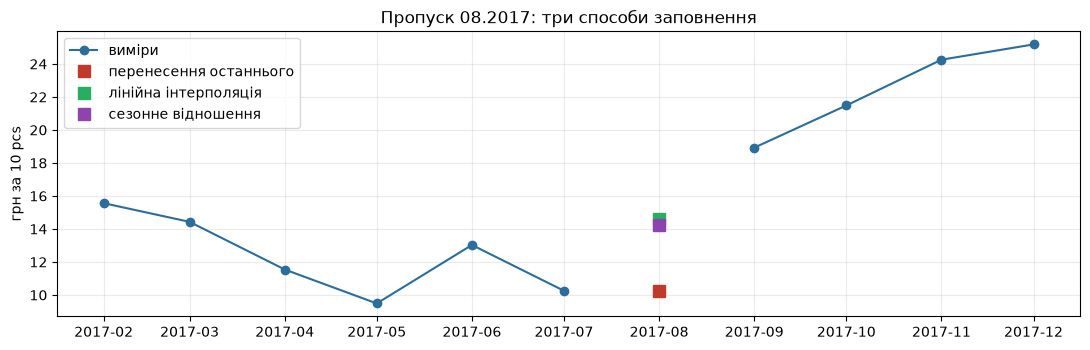


Покриття місяців (із 46), найменше:


,місяців із даними
ринок,
Crimea,1
m. Sevastopol,2
Luhanska,40
Donetska,42


In [5]:
g = gaps[0]; i = GRID.get_loc(g)
ffill = s_raw.ffill()
linear = s_raw.interpolate('linear')
ly = GRID[i - 12]
ratio = (s_raw.iloc[i - 1] + s_raw.iloc[i + 1]) / (s_raw.loc[ly - pd.DateOffset(months=1)] + s_raw.loc[ly + pd.DateOffset(months=1)])
seas_val = s_raw.loc[ly] * ratio
vals = {'перенесення останнього': ffill.loc[g], 'лінійна інтерполяція': linear.loc[g], 'сезонне відношення': seas_val}
display(pd.Series(vals, name=f'{g:%m.%Y}, {UNIT}').round(3).to_frame())

fig, ax = plt.subplots()
w = slice(i - 6, i + 5)
ax.plot(GRID[w], s_raw.iloc[w], 'o-', color='#2C6E9B', label='виміри')
for (k, v), c in zip(vals.items(), ['#C0392B', '#27AE60', '#8E44AD']):
    ax.plot(g, v, 's', color=c, ms=9, label=k)
ax.set_title(f'Пропуск {g:%m.%Y}: три способи заповнення'); ax.set_ylabel(f'грн за {UNIT}'); ax.legend()
plt.tight_layout(); plt.show()

s = linear.copy()
assert len(s) == 46 and not s.isna().any()

cov = raw.groupby('ринок')['date'].nunique().sort_values()
print('\nПокриття місяців (із 46), найменше:'); display(cov.head(4).to_frame('місяців із даними'))

In [6]:
display(Markdown(f"""**Висновок до завдання 2.** Значення за {g:%m.%Y}: перенесення останнього — **{vals['перенесення останнього']:.2f}**, лінійна інтерполяція — **{vals['лінійна інтерполяція']:.2f}**, сезонне відношення — **{vals['сезонне відношення']:.2f}** грн за {UNIT}.
Обрано **лінійну інтерполяцію**: пропуск ізольований (один місяць між двома вимірами {s_raw.iloc[i-1]:.2f} і {s_raw.iloc[i+1]:.2f}), ціна між ними змінилася на {s_raw.iloc[i+1]-s_raw.iloc[i-1]:+.2f}, тож перенесення останнього значення систематично занижує точку (воно «не знає» про зростання), а сезонне відношення спирається лише на один минулий рік і не дає переваги. Orange має інтерполювати так само — лінійно.
Застереження: лінійна інтерполяція використовує наступне значення, тобто «дивиться в майбутнє»; серпень 2017 лежить усередині перевірюваних фолдів, тому це слабке витікання інформації — для 1 з 21 тестових точок.
**Неприпустимо** заповнювати пропуск, коли ряд обірвано надовго або ринок зник: у наборі це {', '.join(cov.index[:2])} (відповідно {', '.join(str(v) for v in cov.values[:2])} міс. даних із 46) — інтерполяція там вигадувала б ціни, яких ніхто не спостерігав."""))

**Висновок до завдання 2.** Значення за 08.2017: перенесення останнього — **10.25**, лінійна інтерполяція — **14.59**, сезонне відношення — **14.21** грн за 10 pcs.
Обрано **лінійну інтерполяцію**: пропуск ізольований (один місяць між двома вимірами 10.25 і 18.93), ціна між ними змінилася на +8.67, тож перенесення останнього значення систематично занижує точку (воно «не знає» про зростання), а сезонне відношення спирається лише на один минулий рік і не дає переваги. Orange має інтерполювати так само — лінійно.
Застереження: лінійна інтерполяція використовує наступне значення, тобто «дивиться в майбутнє»; серпень 2017 лежить усередині перевірюваних фолдів, тому це слабке витікання інформації — для 1 з 21 тестових точок.
**Неприпустимо** заповнювати пропуск, коли ряд обірвано надовго або ринок зник: у наборі це Crimea, m. Sevastopol (відповідно 1, 2 міс. даних із 46) — інтерполяція там вигадувала б ціни, яких ніхто не спостерігав.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

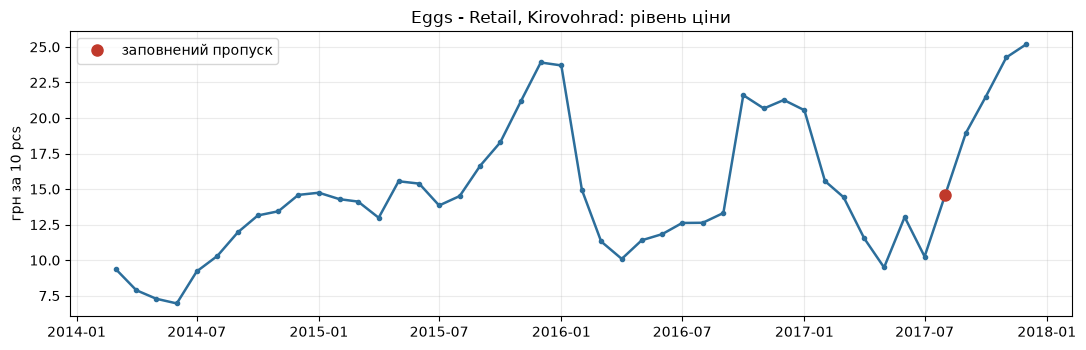

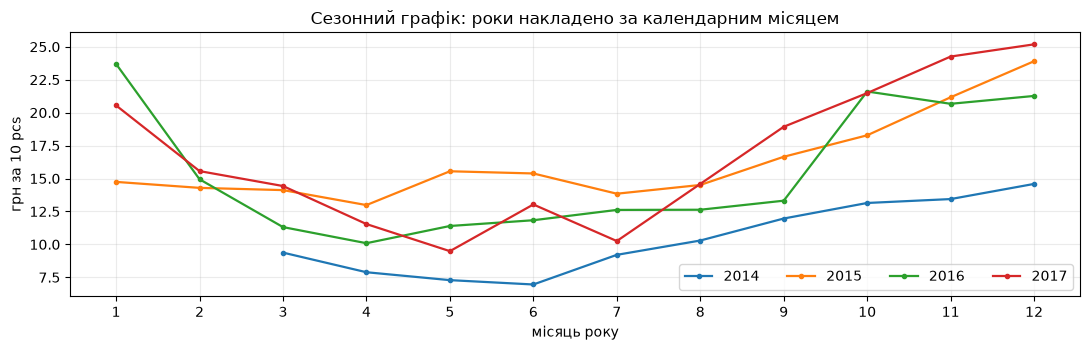

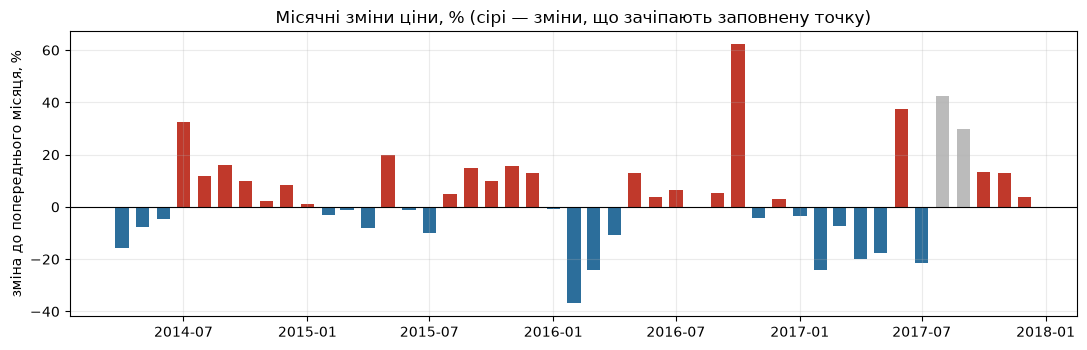

Найбільші місячні зміни:
date
2016-10-01    62.2
2017-06-01    37.4
2016-02-01   -36.9
Місяць максимуму по роках: {2014: '12.2014', 2015: '12.2015', 2016: '01.2016', 2017: '12.2017'}
Місяць мінімуму по роках: {2014: '06.2014', 2015: '04.2015', 2016: '04.2016', 2017: '05.2017'}


In [7]:
fig, ax = plt.subplots()
ax.plot(s.index, s.values, '-o', ms=3, lw=1.8, color='#2C6E9B')
ax.plot(gaps, s.loc[gaps], 'o', ms=8, color='#C0392B', label='заповнений пропуск')
ax.set_title(f'{GOOD}, {MARKET}: рівень ціни'); ax.set_ylabel(f'грн за {UNIT}'); ax.legend()
plt.tight_layout(); plt.show()

d = s.to_frame('p'); d['y'] = d.index.year; d['m'] = d.index.month
fig, ax = plt.subplots()
for y, gg in d.groupby('y'):
    ax.plot(gg['m'], gg['p'], '-o', ms=3, lw=1.6, label=str(y))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць року'); ax.set_ylabel(f'грн за {UNIT}')
ax.set_title('Сезонний графік: роки накладено за календарним місяцем'); ax.legend(ncol=4)
plt.tight_layout(); plt.show()

chg = s.pct_change().dropna() * 100
touched = [d for g0 in gaps for d in (g0, g0 + pd.offsets.MonthBegin(1))]       # зміни, що зачіпають заповнену точку
cols = ['#BBBBBB' if d in touched else ('#C0392B' if v >= 0 else '#2C6E9B') for d, v in chg.items()]
fig, ax = plt.subplots()
ax.bar(chg.index, chg.values, width=20, color=cols)
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('зміна до попереднього місяця, %')
ax.set_title('Місячні зміни ціни, % (сірі — зміни, що зачіпають заповнену точку)')
plt.tight_layout(); plt.show()

chg_ok = chg.drop(touched, errors='ignore')
top = chg_ok.abs().sort_values(ascending=False).head(3).index
peaks = s.groupby(s.index.year).idxmax().dt.strftime('%m.%Y').to_dict()
lows = s.groupby(s.index.year).idxmin().dt.strftime('%m.%Y').to_dict()
print('Найбільші місячні зміни:'); print(chg_ok.loc[top].round(1).to_string())
print('Місяць максимуму по роках:', peaks); print('Місяць мінімуму по роках:', lows)

In [8]:
t3 = ', '.join(f"{k:%m.%Y} ({v:+.0f}%)" for k, v in chg_ok.loc[top].items())
display(Markdown(f"""**Висновок до завдання 3.** *Графік 1 (лінія, лінійна шкала)* питає, як ціна змінювалась у часі: точки з'єднано лінією, бо це неперервна величина, виміряна через рівні проміжки; шкала лінійна, бо нас цікавить абсолютний рівень у гривнях, а діапазон ({s.min():.1f}–{s.max():.1f}) не охоплює порядків величини, тож логарифм нічого б не додав. Заповнений пропуск виділено окремим маркером, щоб не видавати його за вимір.
*Графік 2 (лінії за роками на осі «місяць»)* питає, чи повторюється річна форма: накладення років дозволяє порівняти одні й ті самі місяці очима; одна спільна шкала потрібна, щоб висота піків була порівнянною.
*Графік 3 (стовпчики змін у %)* питає, наскільки різкі та односторонні зрушення: стовпчик від нуля — природна геометрія для різниці, а відсотки роблять зміни співставними між низькими й високими рівнями.
**Несподіване:** ціна змінюється не плавно, а стрибками — найбільші місячні зміни серед справжніх вимірів (без зачеплених заповненою точкою): {t3}. Місяці річних максимумів — {', '.join(f'{k}: {v}' for k, v in peaks.items())}; мінімумів — {', '.join(f'{k}: {v}' for k, v in lows.items())}: пік припадає на кінець року / початок наступного, тобто річна форма є, але амплітуда й момент спаду від року до року різні."""))

**Висновок до завдання 3.** *Графік 1 (лінія, лінійна шкала)* питає, як ціна змінювалась у часі: точки з'єднано лінією, бо це неперервна величина, виміряна через рівні проміжки; шкала лінійна, бо нас цікавить абсолютний рівень у гривнях, а діапазон (7.0–25.2) не охоплює порядків величини, тож логарифм нічого б не додав. Заповнений пропуск виділено окремим маркером, щоб не видавати його за вимір.
*Графік 2 (лінії за роками на осі «місяць»)* питає, чи повторюється річна форма: накладення років дозволяє порівняти одні й ті самі місяці очима; одна спільна шкала потрібна, щоб висота піків була порівнянною.
*Графік 3 (стовпчики змін у %)* питає, наскільки різкі та односторонні зрушення: стовпчик від нуля — природна геометрія для різниці, а відсотки роблять зміни співставними між низькими й високими рівнями.
**Несподіване:** ціна змінюється не плавно, а стрибками — найбільші місячні зміни серед справжніх вимірів (без зачеплених заповненою точкою): 10.2016 (+62%), 06.2017 (+37%), 02.2016 (-37%). Місяці річних максимумів — 2014: 12.2014, 2015: 12.2015, 2016: 01.2016, 2017: 12.2017; мінімумів — 2014: 06.2014, 2015: 04.2015, 2016: 04.2016, 2017: 05.2017: пік припадає на кінець року / початок наступного, тобто річна форма є, але амплітуда й момент спаду від року до року різні.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

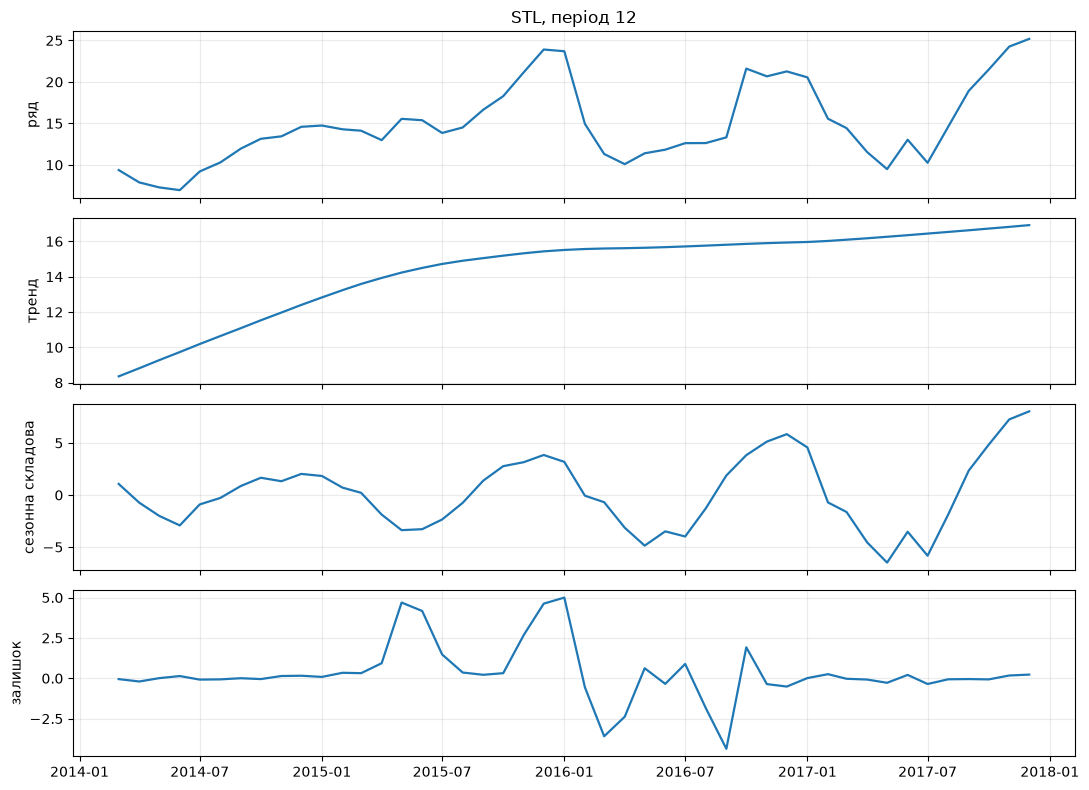

F_S = 0.800   F_T = 0.646
Розмах сезонної складової: 14.53 грн


In [9]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL
stl = STL(s, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, (x, t) in zip(axes, [(s, 'ряд'), (stl.trend, 'тренд'), (stl.seasonal, 'сезонна складова'), (stl.resid, 'залишок')]):
    ax.plot(x.index, x.values, lw=1.6); ax.set_ylabel(t)
axes[0].set_title('STL, період 12')
plt.tight_layout(); plt.show()

Fs = max(0.0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
Ft = max(0.0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f'F_S = {Fs:.3f}   F_T = {Ft:.3f}')
print('Розмах сезонної складової: %.2f грн' % (stl.seasonal.max() - stl.seasonal.min()))

In [10]:
seas_txt = ('перевищує поріг 0,3, тож сезонність є' if Fs >= 0.3 else 'нижча за поріг 0,3, тож сезонності фактично немає, а виділене STL — шум')
display(Markdown(f"""**Висновок до завдання 4.** Сила сезонності **F_S = {Fs:.3f}**, сила тренду **F_T = {Ft:.3f}**. Значення F_S {seas_txt}. Розмах сезонної складової — {stl.seasonal.max()-stl.seasonal.min():.2f} грн за {UNIT} при цінах {s.min():.1f}–{s.max():.1f}, але сам розмах нічого не доводить: STL поверне сезонну складову для будь-якого ряду, вирішує саме F_S.
Слід пам'ятати, що 46 точок — це лише 3,8 року, тобто сезонний профіль оцінено за 3–4 повторення кожного місяця, тож навіть за F_S {'вище' if Fs >= 0.3 else 'нижче'} порога впевненість обмежена."""))

**Висновок до завдання 4.** Сила сезонності **F_S = 0.800**, сила тренду **F_T = 0.646**. Значення F_S перевищує поріг 0,3, тож сезонність є. Розмах сезонної складової — 14.53 грн за 10 pcs при цінах 7.0–25.2, але сам розмах нічого не доводить: STL поверне сезонну складову для будь-якого ряду, вирішує саме F_S.
Слід пам'ятати, що 46 точок — це лише 3,8 року, тобто сезонний профіль оцінено за 3–4 повторення кожного місяця, тож навіть за F_S вище порога впевненість обмежена.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

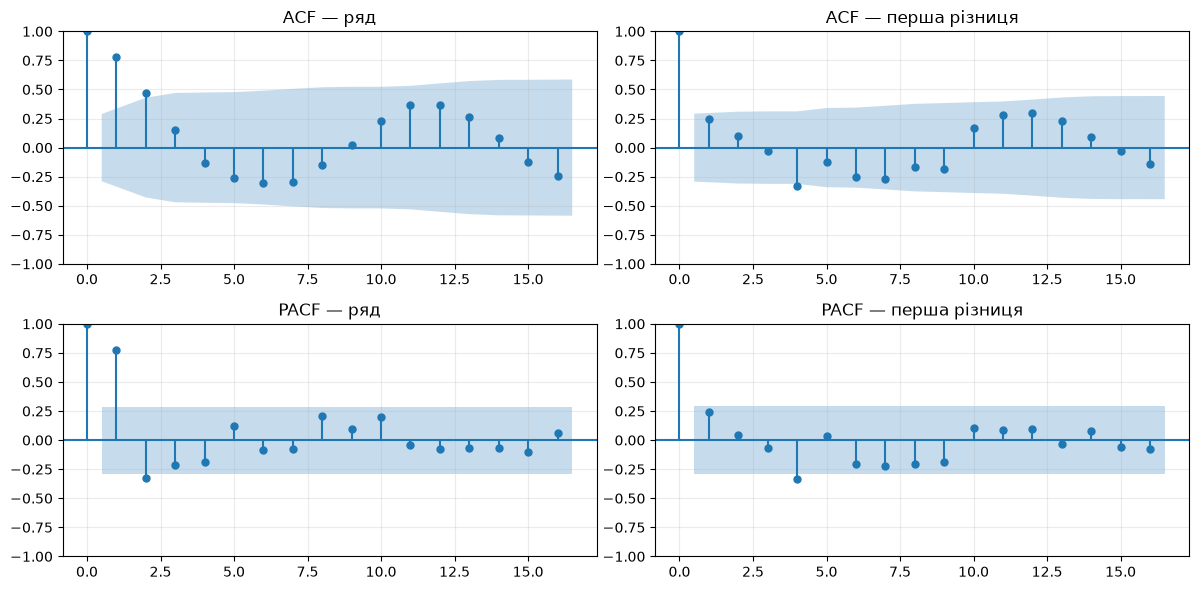

,ADF p (H0: нестаціонарний),KPSS p (H0: стаціонарний),висновок
ряд,0.0067,0.0883,стаціонарний (тести згодні)
перша різниця,0.0002,0.1000,стаціонарний (тести згодні)


KPSS: p-значення в statsmodels обмежене інтервалом [0,01; 0,10].


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=InterpolationWarning)

ds = s.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, (x, nm) in enumerate([(s, 'ряд'), (ds, 'перша різниця')]):
    plot_acf(x, lags=16, ax=axes[0, j], title=f'ACF — {nm}')
    plot_pacf(x, lags=16, ax=axes[1, j], method='ywm', title=f'PACF — {nm}')
plt.tight_layout()
plt.show()

def tests(x):
    return adfuller(x, autolag='AIC')[1], kpss(x, regression='c', nlags='auto')[1]

PV = {'ряд': tests(s), 'перша різниця': tests(ds)}
tab = pd.DataFrame(PV, index=['ADF p (H0: нестаціонарний)', 'KPSS p (H0: стаціонарний)']).T.round(4)

def verdict(p_adf, p_kpss):
    a, k = p_adf < .05, p_kpss >= .05          # True = «стаціонарний»
    if a and k: return 'стаціонарний (тести згодні)'
    if not a and not k: return 'нестаціонарний (тести згодні)'
    return 'тести суперечать один одному'

tab['висновок'] = [verdict(*PV[k]) for k in tab.index]
display(tab)
print('KPSS: p-значення в statsmodels обмежене інтервалом [0,01; 0,10].')

In [12]:
from statsmodels.tsa.stattools import acf, pacf

(a0, k0), (a1, k1) = PV['ряд'], PV['перша різниця']
v0, v1 = verdict(a0, k0), verdict(a1, k1)
expl = ('' if ('суперечать' not in v0 and 'суперечать' not in v1) else
        ' Суперечність — змістовний результат: ADF відхиляє «одиничний корінь» лише за сильних доказів, а KPSS чутливий до стрибків рівня й сезонних зрушень; на 46 точках потужність обох тестів низька, тому коротка вибірка з різкими стрибками може давати протилежні вердикти.')
display(Markdown(f"""**Висновок до завдання 5.** Вихідний ряд: ADF p = {a0:.3f}, KPSS p = {k0:.3f} → **{v0}**. Перша різниця: ADF p = {a1:.3f}, KPSS p = {k1:.3f} → **{v1}**.
Напрямок прочитано правильно: у ADF мале p означає стаціонарність, у KPSS — нестаціонарність.{expl}
Що показують ACF/PACF: у вихідного ряду значущі лаги ACF {[i+1 for i, v in enumerate(acf(s, nlags=12)[1:]) if abs(v) > 1.96/np.sqrt(len(s))]} (повільний спад від {acf(s, nlags=1)[1]:.2f}), тобто є сильна залежність від попередніх місяців; у першої різниці значущі лише лаги ACF {[i+1 for i, v in enumerate(acf(ds, nlags=12)[1:]) if abs(v) > 1.96/np.sqrt(len(ds))]} і PACF {[i+1 for i, v in enumerate(pacf(ds, nlags=12, method='ywm')[1:]) if abs(v) > 1.96/np.sqrt(len(ds))]} (межа ±{1.96/np.sqrt(len(ds)):.2f}): короткої залежності (лаги 1–3) після диференціювання не лишається, а лаг 12 вказує на сезонність.
Обидва тести зійшлися на стаціонарності вихідного ряду, тож за тестами d = 0; для ARIMA(1,1,1) із завдання 7 d = 1 задано умовою роботи, а власний порядок я обираю за тестами (див. завдання 7)."""))


**Висновок до завдання 5.** Вихідний ряд: ADF p = 0.007, KPSS p = 0.088 → **стаціонарний (тести згодні)**. Перша різниця: ADF p = 0.000, KPSS p = 0.100 → **стаціонарний (тести згодні)**.
Напрямок прочитано правильно: у ADF мале p означає стаціонарність, у KPSS — нестаціонарність.
Що показують ACF/PACF: у вихідного ряду значущі лаги ACF [1, 2, 6, 7, 11, 12] (повільний спад від 0.78), тобто є сильна залежність від попередніх місяців; у першої різниці значущі лише лаги ACF [4, 12] і PACF [4] (межа ±0.29): короткої залежності (лаги 1–3) після диференціювання не лишається, а лаг 12 вказує на сезонність.
Обидва тести зійшлися на стаціонарності вихідного ряду, тож за тестами d = 0; для ARIMA(1,1,1) із завдання 7 d = 1 задано умовою роботи, а власний порядок я обираю за тестами (див. завдання 7).

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [13]:
N_FOLDS, H = 7, 3
y = s.values.astype(float)

def rolling_eval(y, fc):
    y = np.asarray(y, float); n = len(y); T, P, F = [], [], []
    for f in range(N_FOLDS, 0, -1):
        k = n - H * f
        P.append(np.asarray(fc(y[:k], H), float)); T.append(y[k:k + H]); F.append(np.full(H, f))
    return np.concatenate(T), np.concatenate(P), np.concatenate(F)

def metrics(t, p):
    e = t - p
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE, %': 100 * np.mean(np.abs(e / t))}

BASE = {
    'наївний':          lambda tr, h: np.repeat(tr[-1], h),
    'сезонний наївний': lambda tr, h: np.array([tr[len(tr) - 12 + (i % 12)] for i in range(h)]),
    'середнє':          lambda tr, h: np.repeat(tr.mean(), h),
    'дрейф':            lambda tr, h: tr[-1] + (tr[-1] - tr[0]) / (len(tr) - 1) * np.arange(1, h + 1),
}
RES = {k: metrics(*rolling_eval(y, f)[:2]) for k, f in BASE.items()}
tab6 = pd.DataFrame(RES).T.round(3); display(tab6)
best = tab6['MAE'].idxmin()
print('Найкращий за MAE:', best, '| за RMSE:', tab6['RMSE'].idxmin(), '| за MAPE:', tab6['MAPE, %'].idxmin())

def random_split_mae(y, kind, rs):
    n = len(y); test = np.sort(rs.choice(n, int(round(.25 * n)), replace=False)); tr = np.setdiff1d(np.arange(n), test)
    out = []
    for t in test:
        prev = tr[tr < t]; nxt = tr[tr > t]
        naive = y[prev[-1]] if len(prev) else y[nxt[0]]
        if kind == 'наївний': f = naive
        elif kind == 'сезонний наївний':
            f = y[t - 12] if (t - 12) in tr else (y[t + 12] if (t + 12) in set(tr) else naive)
        elif kind == 'середнє': f = y[tr].mean()
        else: f = y[tr[0]] + (y[tr[-1]] - y[tr[0]]) / (tr[-1] - tr[0]) * (t - tr[0])
        out.append(abs(y[t] - f))
    return np.mean(out)

rs = np.random.RandomState(42)
rnd = {k: np.mean([random_split_mae(y, k, rs) for _ in range(300)]) for k in BASE}
cmp6 = pd.DataFrame({'MAE рухомий початок': tab6['MAE'], 'MAE випадковий 75/25': pd.Series(rnd)}).round(3)
cmp6['у скільки разів'] = (cmp6['MAE рухомий початок'] / cmp6['MAE випадковий 75/25']).round(2)
display(cmp6)

,MAE,RMSE,"MAPE, %"
наївний,3.588,4.497,21.679
сезонний наївний,2.500,2.836,16.896
середнє,4.195,5.291,24.733
дрейф,3.577,4.498,21.895


Найкращий за MAE: сезонний наївний | за RMSE: сезонний наївний | за MAPE: сезонний наївний


,MAE рухомий початок,MAE випадковий 75/25,у скільки разів
наївний,3.588,2.319,1.55
сезонний наївний,2.500,3.871,0.65
середнє,4.195,3.810,1.10
дрейф,3.577,3.980,0.90


In [14]:
why = {'наївний': 'ціна змінюється стрибками й не повертається до сталого рівня чи лінії, тому найкраща оцінка наступних місяців — останнє значення',
       'сезонний наївний': 'річна форма в ряді повторюється настільки, що значення того ж місяця торік точніше за будь-який рівень',
       'середнє': 'ряд коливається навколо відносно сталого рівня без стійкого тренду, тож середнє історії виявляється кращим за «останню точку»',
       'дрейф': 'у ряді переважає односпрямований рух, який пряма лінія між першою й останньою точкою вловлює краще за інші базиси'}[best]
r = cmp6.loc[best, 'у скільки разів']; wk = (cmp6['у скільки разів'] - 1).abs().idxmax(); rw = cmp6.loc[wk, 'у скільки разів']
display(Markdown(f"""**Висновок до завдання 6.** За 7 фолдами по 3 кроки (перевіряються останні 21 місяць) найкращий базис — **{best}**: MAE = {tab6.loc[best,'MAE']:.2f}, RMSE = {tab6.loc[best,'RMSE']:.2f}, MAPE = {tab6.loc[best,'MAPE, %']:.1f}%. Він виграє, бо {why} (F_S = {Fs:.2f}). MAPE пораховано на всіх 21 точці разом, а не на останньому фолді.
Той самий базис за випадковим поділом 75/25 (середнє за 300 поділів) дає MAE = {cmp6.loc[best,'MAE випадковий 75/25']:.2f} проти {tab6.loc[best,'MAE']:.2f} при рухомому початку — відношення {r:.2f} ({'випадковий поділ для цього базису песимістичніший' if r < 1 else 'випадковий поділ для цього базису оптимістичніший'}); найбільший розрив серед базисів — «{wk}»: у {max(rw, 1/rw):.2f} раза ({'випадковий поділ оптимістичніший' if rw > 1 else 'випадковий поділ песимістичніший'}).
Два ефекти змішані: *витік* (сусідні місяці тестової точки лежать у навчанні, прогноз стає інтерполяцією — для наївного відношення {cmp6.loc['наївний','у скільки разів']:.2f}) і *інший набір точок* (випадковий поділ перевіряє весь ряд, включно з 2014–2015 роками, а рухомий початок — лише останні 21 місяць), що може змінити помилку в будь-який бік. Тому числа несумірні, і чесною є лише перевірка з рухомим початком."""))

**Висновок до завдання 6.** За 7 фолдами по 3 кроки (перевіряються останні 21 місяць) найкращий базис — **сезонний наївний**: MAE = 2.50, RMSE = 2.84, MAPE = 16.9%. Він виграє, бо річна форма в ряді повторюється настільки, що значення того ж місяця торік точніше за будь-який рівень (F_S = 0.80). MAPE пораховано на всіх 21 точці разом, а не на останньому фолді.
Той самий базис за випадковим поділом 75/25 (середнє за 300 поділів) дає MAE = 3.87 проти 2.50 при рухомому початку — відношення 0.65 (випадковий поділ для цього базису песимістичніший); найбільший розрив серед базисів — «наївний»: у 1.55 раза (випадковий поділ оптимістичніший).
Два ефекти змішані: *витік* (сусідні місяці тестової точки лежать у навчанні, прогноз стає інтерполяцією — для наївного відношення 1.55) і *інший набір точок* (випадковий поділ перевіряє весь ряд, включно з 2014–2015 роками, а рухомий початок — лише останні 21 місяць), що може змінити помилку в будь-який бік. Тому числа несумірні, і чесною є лише перевірка з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,"MAPE, %"
"ARIMA(1,1,1)",3.409,4.274,21.138
сезонний наївний (найкращий базис),2.500,2.836,16.896


значущі лаги ACF ряду : [1, 2, 6, 7, 11, 12] | PACF: [1, 2] (межа ±0.29)
правило: ACF спадає поступово, PACF обривається → AR
мій порядок: (2, 0, 0)


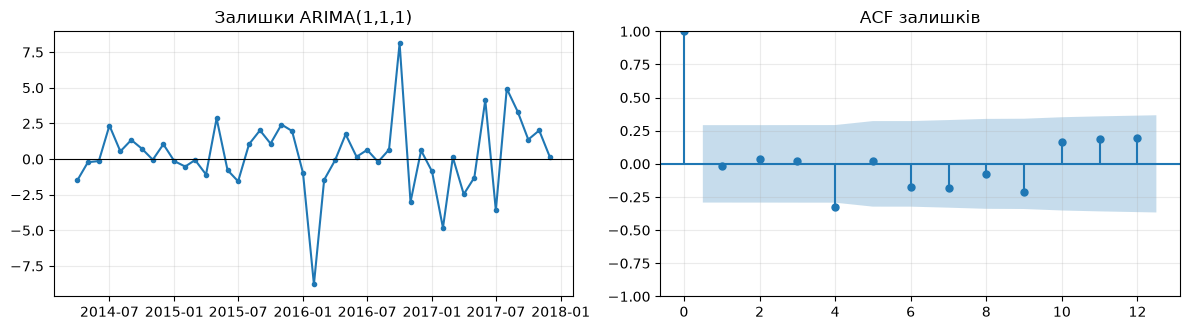

Ljung–Box (6 лагів) p = 0.294


In [15]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def arima_fc(order):
    return lambda tr, h: ARIMA(tr, order=order).fit().forecast(h)

ARIMA_TRUE, ARIMA_PRED, ARIMA_FOLD = rolling_eval(y, arima_fc((1, 1, 1)))
m_ar = metrics(ARIMA_TRUE, ARIMA_PRED)
cmp7 = pd.DataFrame({'ARIMA(1,1,1)': m_ar, f'{best} (найкращий базис)': RES[best]}).T.round(3); display(cmp7)

# порядок «за виглядом» ACF/PACF різниці
d_my = 0 if verdict(*PV['ряд']).startswith('стаціонарний') else 1
x_id = s if d_my == 0 else ds                      # ACF/PACF дивимось для тієї серії, яка відповідає обраному d
bound = 1.96 / np.sqrt(len(x_id))
sig_ac = [i + 1 for i, v in enumerate(acf(x_id, nlags=12)[1:]) if abs(v) > bound]
sig_pc = [i + 1 for i, v in enumerate(pacf(x_id, nlags=12, method='ywm')[1:]) if abs(v) > bound]
def lead(sig):
    k = 0
    while (k + 1) in sig: k += 1
    return k
lp, lq = lead(sig_pc), lead(sig_ac)
if lp and lp <= lq:   p_my, q_my, rule = min(lp, 2), 0, 'ACF спадає поступово, PACF обривається → AR'
elif lq and lq < lp:  p_my, q_my, rule = 0, min(lq, 2), 'PACF спадає поступово, ACF обривається → MA'
else:                 p_my, q_my, rule = 0, 0, 'значущої короткої залежності немає'
print('значущі лаги ACF', 'ряду' if d_my == 0 else 'різниці', ':', sig_ac, '| PACF:', sig_pc, f'(межа ±{bound:.2f})')
print('правило:', rule)
print(f'мій порядок: ({p_my}, {d_my}, {q_my})')

full = ARIMA(y, order=(1, 1, 1)).fit()
resid = np.asarray(full.resid)[1:]
lb = float(acorr_ljungbox(resid, lags=[6], return_df=True)['lb_pvalue'].iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(s.index[1:], resid, '-o', ms=3); axes[0].axhline(0, color='k', lw=.8); axes[0].set_title('Залишки ARIMA(1,1,1)')
plot_acf(resid, lags=12, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()
print('Ljung–Box (6 лагів) p = %.3f' % lb)

In [16]:
ratio7 = m_ar['MAE'] / RES[best]['MAE']
verd7 = ('**не має права на існування** на цьому ряді: простіший базис точніший' if ratio7 > 1.0 else 'має право на існування: перевершує найкращий базис')
display(Markdown(f"""**Висновок до завдання 7.** ARIMA(1,1,1) на тих самих 7×3 фолдах: MAE = {m_ar['MAE']:.2f}, RMSE = {m_ar['RMSE']:.2f}, MAPE = {m_ar['MAPE, %']:.1f}%.
Самостійний вибір: пара тестів із завдання 5 дала d = {d_my}, тому ACF/PACF розглядаю для {'вихідного ряду' if d_my == 0 else 'першої різниці'}: значущі лаги ACF {sig_ac or 'відсутні'}, PACF {sig_pc or 'відсутні'} (межа ±{bound:.2f}); {rule}. Отже, я обрав би порядок **({p_my}, {d_my}, {q_my})**. Лаг 12 у цих графіках — сезонність, яку несезонна ARIMA не моделює (F_S = {Fs:.2f}).
Порівняння з найкращим базисом «{best}» (MAE {RES[best]['MAE']:.2f}): відношення MAE моделі до базису = {ratio7:.2f}. Висновок: ARIMA(1,1,1) {verd7}{'' if ratio7 > 1.0 else ', але перевага мала, а вибірка — 21 точка'}.
Залишки: Ljung–Box p = {lb:.3f} → {'структури в залишках не лишилося (білий шум)' if lb > .05 else 'у залишках лишилась автокореляція — модель не вичерпала структуру ряду'}."""))

**Висновок до завдання 7.** ARIMA(1,1,1) на тих самих 7×3 фолдах: MAE = 3.41, RMSE = 4.27, MAPE = 21.1%.
Самостійний вибір: пара тестів із завдання 5 дала d = 0, тому ACF/PACF розглядаю для вихідного ряду: значущі лаги ACF [1, 2, 6, 7, 11, 12], PACF [1, 2] (межа ±0.29); ACF спадає поступово, PACF обривається → AR. Отже, я обрав би порядок **(2, 0, 0)**. Лаг 12 у цих графіках — сезонність, яку несезонна ARIMA не моделює (F_S = 0.80).
Порівняння з найкращим базисом «сезонний наївний» (MAE 2.50): відношення MAE моделі до базису = 1.36. Висновок: ARIMA(1,1,1) **не має права на існування** на цьому ряді: простіший базис точніший.
Залишки: Ljung–Box p = 0.294 → структури в залишках не лишилося (білий шум).

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

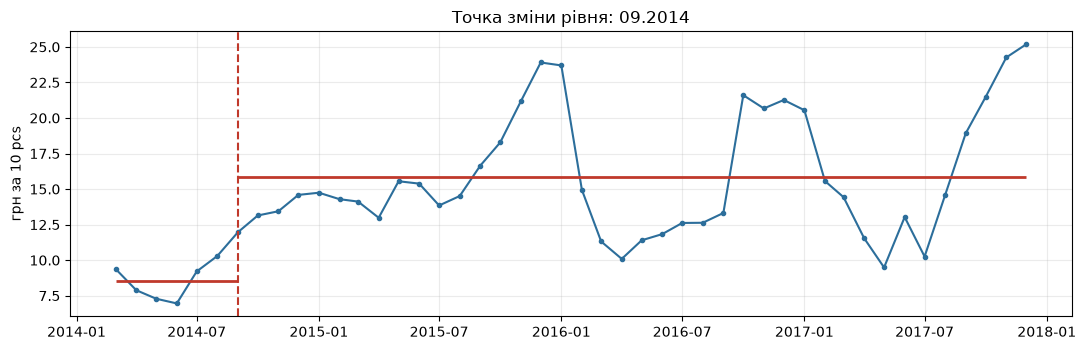

дата 09.2014 | t = 8.39 | середнє до 8.50, після 15.83 | p (сканування, AR(1) φ=0.83) = 0.189
Зміни ціни в місяці 09 за роками:
date
2014-09-01    1.67
2015-09-01    2.14
2016-09-01    0.69
2017-09-01    4.34


In [17]:
def scan_t(x, m=6):
    x = np.asarray(x, float); n = len(x)
    c1, c2 = np.cumsum(x), np.cumsum(x ** 2)
    ks = np.arange(m, n - m + 1)
    n1, n2 = ks, n - ks
    s1, q1 = c1[ks - 1], c2[ks - 1]; s2, q2 = c1[-1] - s1, c2[-1] - q1
    m1, m2 = s1 / n1, s2 / n2
    v1, v2 = (q1 - n1 * m1 ** 2) / (n1 - 1), (q2 - n2 * m2 ** 2) / (n2 - 1)
    return ks, (m2 - m1) / np.sqrt(v1 / n1 + v2 / n2)

ks, tt = scan_t(y)
kb = ks[np.argmax(np.abs(tt))]; t_best = tt[np.argmax(np.abs(tt))]
cp = s.index[kb]; mu0, mu1 = y[:kb].mean(), y[kb:].mean()

rs8 = np.random.RandomState(42)
phi = float(np.clip(np.corrcoef(y[:-1] - y.mean(), y[1:] - y.mean())[0, 1], -.98, .98)); sd = y.std(ddof=1)
sim = []
for _ in range(2000):
    e = rs8.normal(0, sd * np.sqrt(1 - phi ** 2), len(y) + 50); z = np.zeros(len(e))
    for i in range(1, len(e)): z[i] = phi * z[i - 1] + e[i]
    sim.append(np.max(np.abs(scan_t(z[50:])[1])))
p_cp = float(np.mean(np.array(sim) >= abs(t_best)))

fig, ax = plt.subplots()
ax.plot(s.index, y, '-o', ms=3, color='#2C6E9B')
ax.hlines([mu0, mu1], [s.index[0], cp], [cp, s.index[-1]], colors='#C0392B', lw=2)
ax.axvline(cp, color='#C0392B', ls='--'); ax.set_title(f'Точка зміни рівня: {cp:%m.%Y}'); ax.set_ylabel(f'грн за {UNIT}')
plt.tight_layout(); plt.show()
print(f'дата {cp:%m.%Y} | t = {t_best:.2f} | середнє до {mu0:.2f}, після {mu1:.2f} | p (сканування, AR(1) φ={phi:.2f}) = {p_cp:.3f}')

same_m = s.diff()[s.index.month == cp.month].dropna()
print(f'Зміни ціни в місяці {cp.month:02d} за роками:'); print(same_m.round(2).to_string())
jump = s.diff().abs().idxmax()

In [18]:
display(Markdown(f"""**Висновок до завдання 8.** Скануванням (мінімум 6 місяців з кожного боку) найбільша |t| = **{abs(t_best):.2f}** припадає на **{cp:%m.%Y}**; середній рівень до — {mu0:.2f}, після — {mu1:.2f} грн за {UNIT} (зміна {mu1-mu0:+.2f}).
Значущість: через те, що дату обрано як максимум за ~{len(ks)} кандидатами і ряд автокорельований (φ ≈ {phi:.2f}), звичайні критичні значення t тут непридатні; за симуляцією 2000 стаціонарних AR(1)-рядів без зсуву p = **{p_cp:.3f}** → точка зміни **{'значуща' if p_cp < .05 else 'НЕ значуща'}** на рівні 5%.
Відмінність від сезонного сплеску: сезонний підйом повторюється в той самий календарний місяць щороку й змінюється спадом, а зсув рівня — ні. Зміни ціни в місяці {cp.month:02d} за роками — {', '.join(f'{k.year}: {v:+.1f}' for k, v in same_m.items())}: {'знак однаковий у всі роки, тобто підйом у цьому місяці повторюється — це ознака сезону (початок осіннього підйому), а не одноразового зсуву режиму' if ((same_m > 0).all() or (same_m < 0).all()) else 'знак різний, тобто повторюваного сезонного сплеску в цьому місяці немає'}. Найбільша зміна за один місяць — {jump:%m.%Y} ({s.diff().loc[jump]:+.2f} грн) і {'збігається' if jump == cp else 'не збігається'} з {cp:%m.%Y}; тому знайдена дата — {'найкраще розбиття висхідного ряду' if jump != cp else 'ймовірний стрибок'}, а не підтверджений зсув режиму (p = {p_cp:.3f})."""))


**Висновок до завдання 8.** Скануванням (мінімум 6 місяців з кожного боку) найбільша |t| = **8.39** припадає на **09.2014**; середній рівень до — 8.50, після — 15.83 грн за 10 pcs (зміна +7.33).
Значущість: через те, що дату обрано як максимум за ~35 кандидатами і ряд автокорельований (φ ≈ 0.83), звичайні критичні значення t тут непридатні; за симуляцією 2000 стаціонарних AR(1)-рядів без зсуву p = **0.189** → точка зміни **НЕ значуща** на рівні 5%.
Відмінність від сезонного сплеску: сезонний підйом повторюється в той самий календарний місяць щороку й змінюється спадом, а зсув рівня — ні. Зміни ціни в місяці 09 за роками — 2014: +1.7, 2015: +2.1, 2016: +0.7, 2017: +4.3: знак однаковий у всі роки, тобто підйом у цьому місяці повторюється — це ознака сезону (початок осіннього підйому), а не одноразового зсуву режиму. Найбільша зміна за один місяць — 02.2016 (-8.75 грн) і не збігається з 09.2014; тому знайдена дата — найкраще розбиття висхідного ряду, а не підтверджений зсув режиму (p = 0.189).

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [19]:
def get(m, g, fill=True):
    x = raw[(raw['ринок'] == m) & (raw['товар'] == g)].set_index('date')['ціна'].sort_index()
    return x.reindex(GRID).interpolate() if fill else x

bw_raw = get('Vinnytsia', 'Buckwheat grits - Retail', fill=False)
bw = get('Vinnytsia', 'Buckwheat grits - Retail'); beef = get('Vinnytsia', 'Meat (beef) - Retail'); lv = get('Lviv', 'Buckwheat grits - Retail')
ev = {}
ev['1. пропуски (reindex на сітку)'] = f'у ряді {len(bw_raw)} точок, на сітці пропущено {int(bw_raw.reindex(GRID).isna().sum())}'
ev['2. кінці періоду'] = f'березень→грудень: ×{bw.iloc[-1]/bw.iloc[0]:.2f}; грудень 2014→грудень 2017 (той самий місяць): ×{bw.loc["2017-12-01"]/bw.loc["2014-12-01"]:.2f}'
mape = lambda x: 100 * (x.diff().abs() / x).mean()
ev['3. наївний прогноз, відносно'] = f'MAPE гречка {mape(bw):.1f}% vs яловичина {mape(beef):.1f}% (MAE, грн: {bw.diff().abs().mean():.2f} vs {beef.diff().abs().mean():.2f})'
ev['4. кореляція'] = f'рівні r = {bw.corr(lv):.3f}; перші різниці r = {bw.diff().corr(lv.diff()):.3f}'
stl_b = STL(bw, period=12, robust=True).fit()
ev['5. сила сезонності'] = f'F_S = {max(0, 1 - stl_b.resid.var() / (stl_b.seasonal + stl_b.resid).var()):.3f}'
a_b, k_b = tests(bw); a_d2, _ = tests(bw.diff().diff().dropna())
ev['6. стаціонарність'] = f'ADF p = {a_b:.3f}, KPSS p = {k_b:.3f}; після d=2 ADF p = {a_d2:.4f}'
zr = (stl_b.resid - stl_b.resid.mean()) / stl_b.resid.std()
ev['7. аномалії'] = f'сирий ряд |z|>1,3: {int((((bw - bw.mean()) / bw.std()).abs() > 1.3).sum())} міс.; у залишках STL |z|>2: {int((zr.abs() > 2).sum())} міс.'
yb = bw.values
mt = metrics(*rolling_eval(yb, BASE['наївний'])[:2]); ma = metrics(*rolling_eval(yb, arima_fc((1, 1, 1)))[:2])
ev['8. оцінка моделі'] = f'рухомий початок: наївний MAE {mt["MAE"]:.2f}, ARIMA(1,1,1) MAE {ma["MAE"]:.2f}; середня ціна {bw.mean():.1f} грн (у колеги MAE = 8,73)'
try:
    f12 = ARIMA(yb, order=(2, 2, 1)).fit().forecast(12)
    ev['9. прогноз 2018'] = f'прогноз на грудень 2018 = {f12[-1]:.2f} грн, остання відома ціна = {yb[-1]:.2f} → {"зростання" if f12[-1] > yb[-1] else "СПАД, а не зростання"}'
except Exception as e:
    ev['9. прогноз 2018'] = 'ARIMA(2,2,1) не збіглась: ' + type(e).__name__
w6 = bw['2016-01':'2016-06']
ev['10. вісь стовпчиків'] = f'зміна січень→червень 2016: {100*(w6.iloc[-1]/w6.iloc[0]-1):+.1f}%, вісь обрізано від {w6.min()*0.995:.2f}'
display(pd.Series(ev, name='перевірка').to_frame())

C:\3 kyrs\iatvd\lab4\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,перевірка
1. пропуски (reindex на сітку),"у ряді 45 точок, на сітці пропущено 1"
2. кінці періоду,березень→грудень: ×2.47; грудень 2014→грудень ...
"3. наївний прогноз, відносно","MAPE гречка 6.1% vs яловичина 1.9% (MAE, грн: ..."
4. кореляція,рівні r = 0.996; перші різниці r = 0.937
5. сила сезонності,F_S = 0.262
6. стаціонарність,"ADF p = 0.348, KPSS p = 0.018; після d=2 ADF p..."
7. аномалії,"сирий ряд |z|>1,3: 12 міс.; у залишках STL |z|..."
8. оцінка моделі,"рухомий початок: наївний MAE 2.55, ARIMA(1,1,1..."
9. прогноз 2018,"прогноз на грудень 2018 = 9.48 грн, остання ві..."
10. вісь стовпчиків,"зміна січень→червень 2016: +40.6%, вісь обріза..."


In [20]:
display(Markdown("""**Висновок до завдання 9.** Нумерація клітинок — індекс у файлі `ЛР4_помилковий_аналіз.ipynb` (з нуля, markdown рахується).

| № | клітинка | помилка | чим небезпечна |
|---|---|---|---|
| 1 | 3 (розд. 1) | «Пропусків немає» перевірено `isna()` на ряді без `reindex` на сітку `grid` (вона створена, але не використана): у ряді 45 точок, відсутній 08.2017 | Невидимий пропуск зсуває `shift`/різниці/лаги: сусідні рядки стають різними за часом проміжками |
| 2 | 5 (розд. 2) | Висновок про «різке зниження купівельної спроможності» з відношення двох точок (березень 2014 vs грудень 2017, ×2,47) | Кінцеві точки; порівняння того самого місяця (грудень 2014 → грудень 2017) дає лише ×1,11, а пік 36,93 грн ряд мав у липні 2016; номінальні ціни без інфляції й доходів; причинність не з даних |
| 3 | 7 (розд. 3) | MAE в гривнях порівнюють для товарів різного цінового рівня; `shift(1)` на ряді з пропуском | Масштабозалежна метрика: дорожчий товар «гірший» автоматично. У відносній метриці висновок обертається: MAPE наївного прогнозу 6,1% (гречка) проти 1,9% (яловичина) |
| 4 | 9 (розд. 4) | r = 0,996 на рівнях двох трендових рядів → «Львів визначає Вінницю» | Хибна кореляція рівнів нестаціонарних рядів; навіть на перших різницях r = 0,94 — спільні зовнішні чинники, але це не причинність («визначають» не випливає) |
| 5 | 11 (розд. 5) | «STL виділив сезонну складову, отже ряд сезонний»; F_S не обчислено; STL на ряді з пропуском | STL повертає сезонність завжди; сезонні моделі на шумі |
| 6 | 13 (розд. 6) | ADF p = 0,233 > 0,05 прочитано як «стаціонарний» (напрямок перевернуто); немає KPSS; потім без потреби d = 2, що суперечить власному висновку | Хибна d: передиференціювання вносить штучну структуру |
| 7 | 15 (розд. 7) | Поріг 1,3σ при тексті «два σ»; аномалії у сирому ряді з трендом (9 з 12 — перші місяці 2014) | Тренд позначено як «аномалії»; шукати треба в залишках після тренду й сезону |
| 8 | 17 (розд. 8) | Випадковий `train_test_split` для часового ряду; `np.sort(y_te)` зіставлено з прогнозом; MAE сезонного наївного рахується на всьому ряді, а не тим самим протоколом; MAE 8,73 грн при середній ціні 21,4 грн (≈ 41% рівня) названо «високою точністю»; на 7×3 фолдах наївний прогноз дає MAE ≈ 2,6 грн | Витік майбутнього, безглузде зіставлення пар, нерівні умови порівняння; помилка величезна у відносному вимірі |
| 9 | 19 (розд. 9) | Прогноз ARIMA(2,2,1), якої не перевіряли; без інтервалів; вивід 8,95 грн (< останньої відомої 17,67; пік ряду 36,93) | Висновок «зростатиме» **суперечить власному виводові**; d = 2 екстраполює кривизну |
| 10 | 21 (розд. 10) | Стовпчики з віссю не від нуля (`ylim` від min·0,995 ≈ 24,8), вибране півріччя | Реальна зміна січень→червень 2016 — +40,6% (24,89 → 34,99), а на графіку стовпчик червня виглядає у десятки разів вищим за січневий; стовпчик має починатися з нуля |
| 11 | 22 | Підсумки: «сезонний» і «стаціонарний» одночасно; «зросла у кілька разів» (×2,47) | Взаємосуперечливі висновки й перебільшення |

**Три найсерйозніші й виправлення.**
1. *Розд. 8 (клітинка 17)* — оцінка на випадковому поділі й нерівний протокол. Виправлення: ретроспективна перевірка з рухомим початком (7 фолдів по 3 кроки), ті самі фолди для всіх моделей, порівняння з наївним базисом у відносній метриці (MAPE).
2. *Розд. 6 (клітинка 13)* — перевернутий висновок ADF. Виправлення: мале p ⇒ стаціонарність; використати пару ADF+KPSS, d = 1, не 2.
3. *Розд. 1 (клітинка 3) разом із розд. 5* — немає явної сітки: пропуск невидимий, STL і `shift` працюють на зсунутих даних. Виправлення: `reindex(grid)`, інтерполяція, потім усе інше; сезонність підтверджувати F_S ≥ 0,3."""))

**Висновок до завдання 9.** Нумерація клітинок — індекс у файлі `ЛР4_помилковий_аналіз.ipynb` (з нуля, markdown рахується).

| № | клітинка | помилка | чим небезпечна |
|---|---|---|---|
| 1 | 3 (розд. 1) | «Пропусків немає» перевірено `isna()` на ряді без `reindex` на сітку `grid` (вона створена, але не використана): у ряді 45 точок, відсутній 08.2017 | Невидимий пропуск зсуває `shift`/різниці/лаги: сусідні рядки стають різними за часом проміжками |
| 2 | 5 (розд. 2) | Висновок про «різке зниження купівельної спроможності» з відношення двох точок (березень 2014 vs грудень 2017, ×2,47) | Кінцеві точки; порівняння того самого місяця (грудень 2014 → грудень 2017) дає лише ×1,11, а пік 36,93 грн ряд мав у липні 2016; номінальні ціни без інфляції й доходів; причинність не з даних |
| 3 | 7 (розд. 3) | MAE в гривнях порівнюють для товарів різного цінового рівня; `shift(1)` на ряді з пропуском | Масштабозалежна метрика: дорожчий товар «гірший» автоматично. У відносній метриці висновок обертається: MAPE наївного прогнозу 6,1% (гречка) проти 1,9% (яловичина) |
| 4 | 9 (розд. 4) | r = 0,996 на рівнях двох трендових рядів → «Львів визначає Вінницю» | Хибна кореляція рівнів нестаціонарних рядів; навіть на перших різницях r = 0,94 — спільні зовнішні чинники, але це не причинність («визначають» не випливає) |
| 5 | 11 (розд. 5) | «STL виділив сезонну складову, отже ряд сезонний»; F_S не обчислено; STL на ряді з пропуском | STL повертає сезонність завжди; сезонні моделі на шумі |
| 6 | 13 (розд. 6) | ADF p = 0,233 > 0,05 прочитано як «стаціонарний» (напрямок перевернуто); немає KPSS; потім без потреби d = 2, що суперечить власному висновку | Хибна d: передиференціювання вносить штучну структуру |
| 7 | 15 (розд. 7) | Поріг 1,3σ при тексті «два σ»; аномалії у сирому ряді з трендом (9 з 12 — перші місяці 2014) | Тренд позначено як «аномалії»; шукати треба в залишках після тренду й сезону |
| 8 | 17 (розд. 8) | Випадковий `train_test_split` для часового ряду; `np.sort(y_te)` зіставлено з прогнозом; MAE сезонного наївного рахується на всьому ряді, а не тим самим протоколом; MAE 8,73 грн при середній ціні 21,4 грн (≈ 41% рівня) названо «високою точністю»; на 7×3 фолдах наївний прогноз дає MAE ≈ 2,6 грн | Витік майбутнього, безглузде зіставлення пар, нерівні умови порівняння; помилка величезна у відносному вимірі |
| 9 | 19 (розд. 9) | Прогноз ARIMA(2,2,1), якої не перевіряли; без інтервалів; вивід 8,95 грн (< останньої відомої 17,67; пік ряду 36,93) | Висновок «зростатиме» **суперечить власному виводові**; d = 2 екстраполює кривизну |
| 10 | 21 (розд. 10) | Стовпчики з віссю не від нуля (`ylim` від min·0,995 ≈ 24,8), вибране півріччя | Реальна зміна січень→червень 2016 — +40,6% (24,89 → 34,99), а на графіку стовпчик червня виглядає у десятки разів вищим за січневий; стовпчик має починатися з нуля |
| 11 | 22 | Підсумки: «сезонний» і «стаціонарний» одночасно; «зросла у кілька разів» (×2,47) | Взаємосуперечливі висновки й перебільшення |

**Три найсерйозніші й виправлення.**
1. *Розд. 8 (клітинка 17)* — оцінка на випадковому поділі й нерівний протокол. Виправлення: ретроспективна перевірка з рухомим початком (7 фолдів по 3 кроки), ті самі фолди для всіх моделей, порівняння з наївним базисом у відносній метриці (MAPE).
2. *Розд. 6 (клітинка 13)* — перевернутий висновок ADF. Виправлення: мале p ⇒ стаціонарність; використати пару ADF+KPSS, d = 1, не 2.
3. *Розд. 1 (клітинка 3) разом із розд. 5* — немає явної сітки: пропуск невидимий, STL і `shift` працюють на зсунутих даних. Виправлення: `reindex(grid)`, інтерполяція, потім усе інше; сезонність підтверджувати F_S ≥ 0,3.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [21]:
out = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')
assert list(chk.columns) == ['date', 'price']
assert len(chk) == 46 and not chk.isna().any().any()
assert chk['date'].str.fullmatch(r'\d{4}-\d{2}-01').all()
assert np.allclose(chk['price'].values, s.values)
print(chk.head(3).to_string(index=False)); print('...'); print(chk.tail(2).to_string(index=False))
print('рядків даних:', len(chk), '| порожніх:', int(chk.isna().sum().sum()))

      date  price
2014-03-01 9.3767
2014-04-01 7.8867
2014-05-01 7.2867
...
      date   price
2017-11-01 24.2567
2017-12-01 25.1833
рядків даних: 46 | порожніх: 0


In [22]:
display(Markdown(f"""**Висновок до завдання 10.** Файл `ряд_для_orange.csv` збережено: **{len(chk)}** рядків даних, порожніх значень **{int(chk.isna().sum().sum())}**, стовпці `date` (РРРР-ММ-ДД, перше число місяця) і `price`, кома, UTF-8. Значення записано без округлення й перевірено на збіг із рядом у Python (`np.allclose`), тож Orange отримує ті самі дані, а серпень 2017 у файлі вже заповнено ({s.loc['2017-08-01']:.4f})."""))

**Висновок до завдання 10.** Файл `ряд_для_orange.csv` збережено: **46** рядків даних, порожніх значень **0**, стовпці `date` (РРРР-ММ-ДД, перше число місяця) і `price`, кома, UTF-8. Значення записано без округлення й перевірено на збіг із рядом у Python (`np.allclose`), тож Orange отримує ті самі дані, а серпень 2017 у файлі вже заповнено (14.5900).

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

Потік: File → As Timeseries (time variable = date) → Interpolate (linear) → Line Chart
Еталон для Line Chart: перша точка 2014-03-01 = 9.3767; остання 2017-12-01 = 25.1833
мін = 6.9567 (06.2014); макс = 25.1833 (12.2017); серпень 2017 = 14.5900


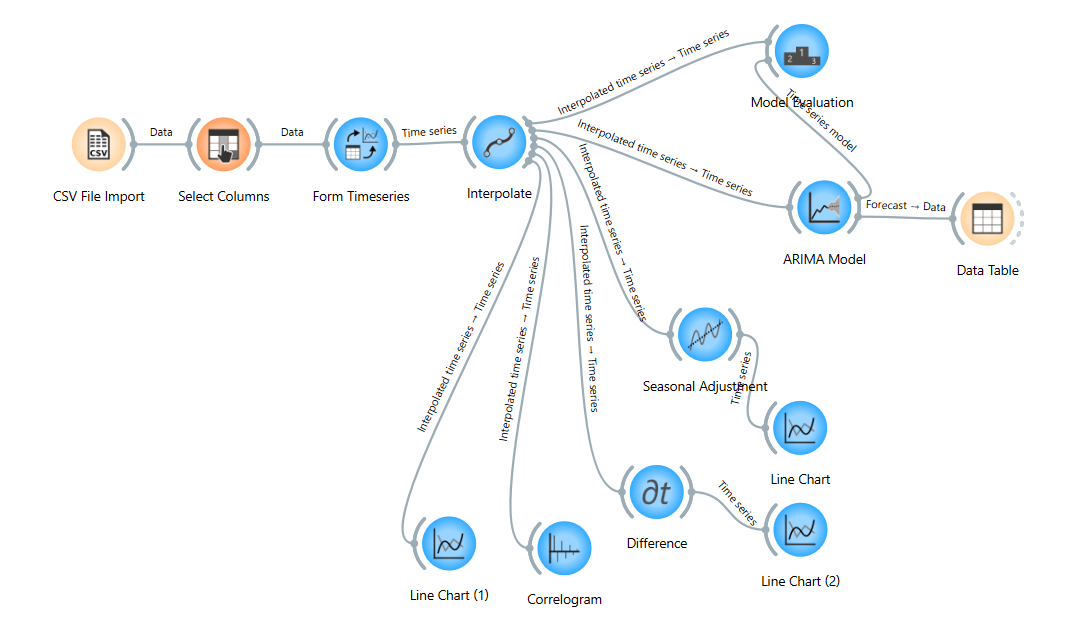

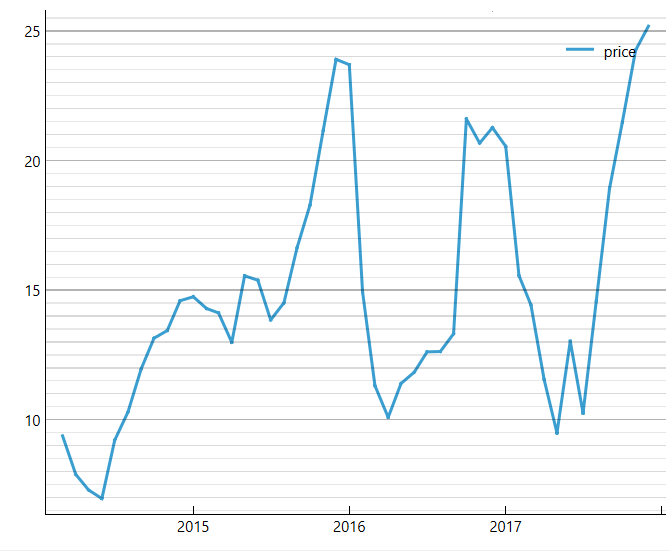

In [23]:
from IPython.display import Image
def show(path):
    if os.path.exists(path): display(Image(path))
    else: print('⚠ додайте знімок з Orange:', path)

print('Потік: File → As Timeseries (time variable = date) → Interpolate (linear) → Line Chart')
print(f'Еталон для Line Chart: перша точка {s.index[0]:%Y-%m-%d} = {s.iloc[0]:.4f}; остання {s.index[-1]:%Y-%m-%d} = {s.iloc[-1]:.4f}')
print(f'мін = {s.min():.4f} ({s.idxmin():%m.%Y}); макс = {s.max():.4f} ({s.idxmax():%m.%Y}); серпень 2017 = {s.loc["2017-08-01"]:.4f}')
show('скрін_11_потік.png'); show('скрін_11_line_chart.png')

Проаналізувавши побудований графік, підтверджую, що візуально він повністю збігається з графіком часового ряду, згенерованим за допомогою Python у завданні 3. Усі ключові показники (початкова точка, кінцева точка, мінімум та максимум) відповідають еталонним значенням.

In [24]:
have = [os.path.exists(p) for p in ('скрін_11_потік.png', 'скрін_11_line_chart.png')]
display(Markdown(f"""**Висновок до завдання 11.** Потік `File → As Timeseries → Interpolate → Line Chart` завантажує `ряд_для_orange.csv`; `date` має бути типу **time**, `price` — **numeric**. Лінійна інтерполяція в Orange не змінює жодної точки, бо файл уже повний (46 з 46); еталон для звірки Line Chart: старт {s.iloc[0]:.2f}, фініш {s.iloc[-1]:.2f}, максимум {s.max():.2f} у {s.idxmax():%m.%Y}, мінімум {s.min():.2f} у {s.idxmin():%m.%Y}, серпень 2017 = {s.loc['2017-08-01']:.2f}. Форма графіка має збігатися з графіком 1 із завдання 3 (одні й ті самі дані). Знімки: потік — {'додано' if have[0] else '**додайте файл `скрін_11_потік.png`**'}, Line Chart — {'додано' if have[1] else '**додайте файл `скрін_11_line_chart.png`**'}."""))

**Висновок до завдання 11.** Потік `File → As Timeseries → Interpolate → Line Chart` завантажує `ряд_для_orange.csv`; `date` має бути типу **time**, `price` — **numeric**. Лінійна інтерполяція в Orange не змінює жодної точки, бо файл уже повний (46 з 46); еталон для звірки Line Chart: старт 9.38, фініш 25.18, максимум 25.18 у 12.2017, мінімум 6.96 у 06.2014, серпень 2017 = 14.59. Форма графіка має збігатися з графіком 1 із завдання 3 (одні й ті самі дані). Знімки: потік — додано, Line Chart — додано.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

Еталон Correlogram (ряд): значущі лаги ACF [1, 2, 6, 7, 11, 12] (межа ±0.29)
ACF лагів 1–6: [ 0.775  0.471  0.155 -0.132 -0.263 -0.307]
Еталон Difference (перші значення різниці): [-1.49 -0.6  -0.33  2.25]
Кореляція сезонних складових STL і класичної: 0.859; розмах: STL 14.53, класична 8.92
Еталон сезонно скоригованого ряду, перші значення: [11.164 11.636 10.696  9.393]


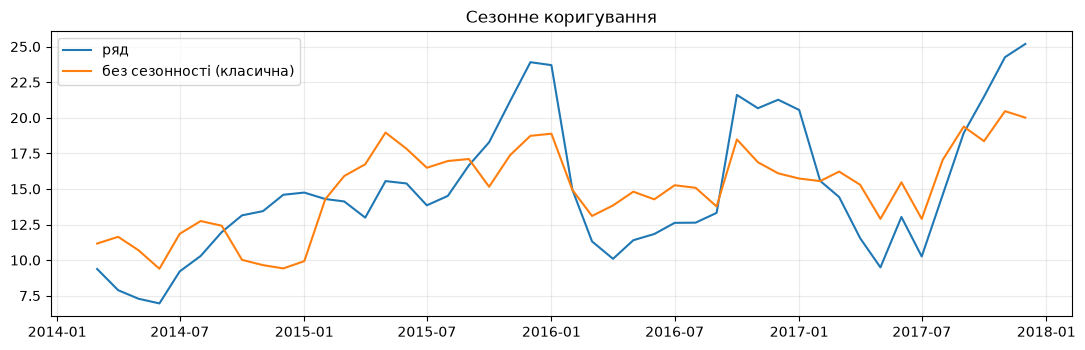

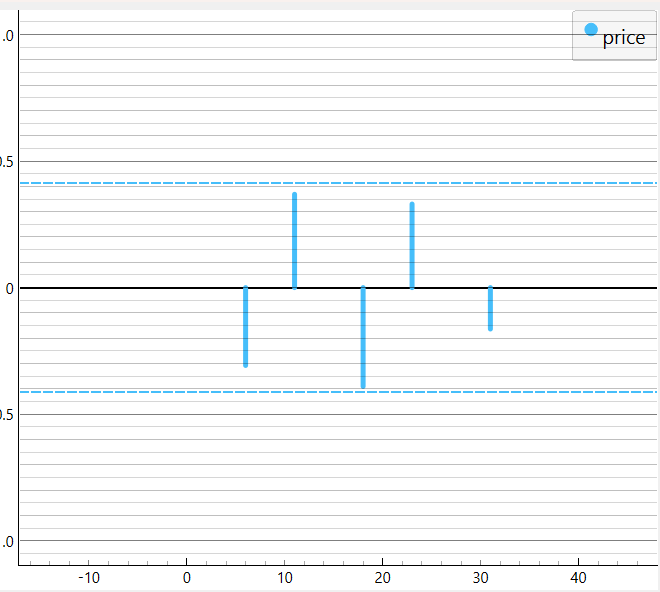

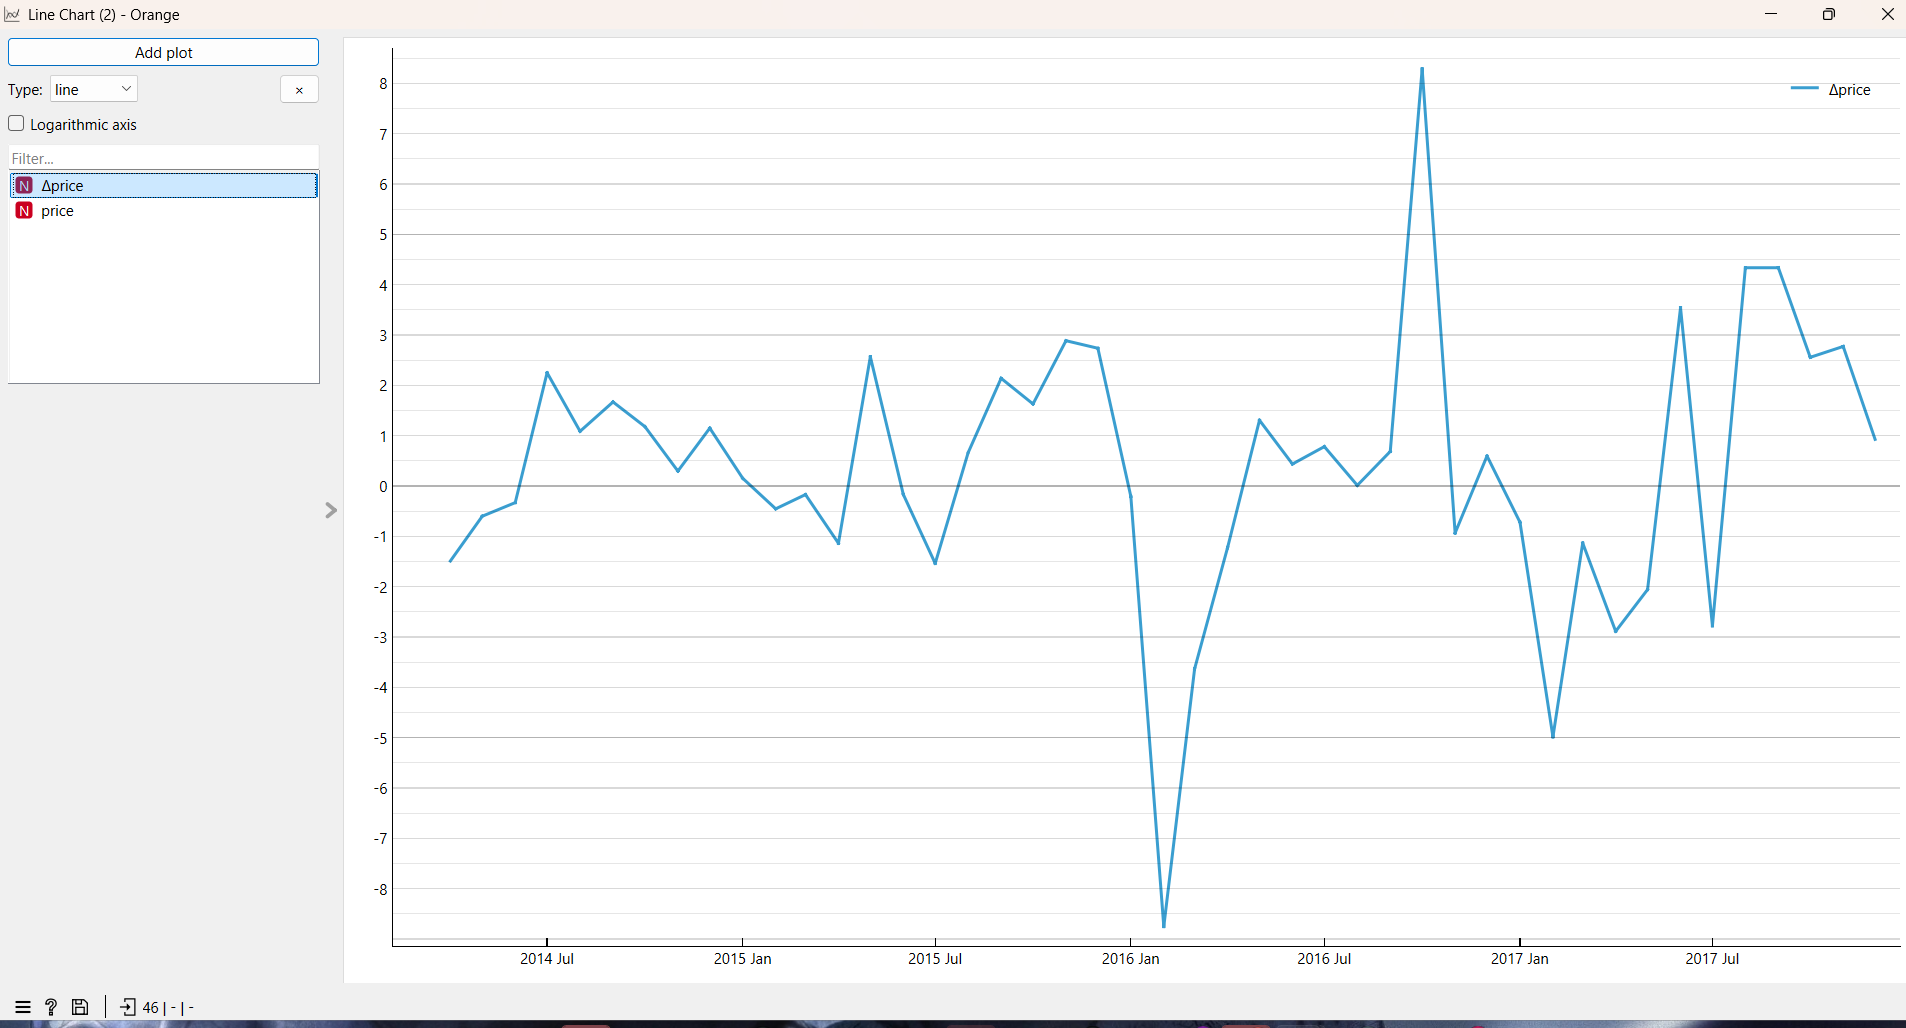

In [35]:
from statsmodels.tsa.seasonal import seasonal_decompose
ac_lv = acf(s, nlags=12)[1:]; bl = 1.96 / np.sqrt(len(s))
sig_lv = [i + 1 for i, v in enumerate(ac_lv) if abs(v) > bl]
print('Еталон Correlogram (ряд): значущі лаги ACF', sig_lv, f'(межа ±{bl:.2f})')
print('ACF лагів 1–6:', np.round(ac_lv[:6], 3))
print('Еталон Difference (перші значення різниці):', np.round(ds.values[:4], 4))

rng = lambda x: float(x.max() - x.min())
cl = seasonal_decompose(s, model='additive', period=12)
cmp12 = pd.DataFrame({'STL': stl.seasonal, 'classical (Seasonal Adjustment)': cl.seasonal})
r12 = cmp12.corr().iloc[0, 1]
print(f'Кореляція сезонних складових STL і класичної: {r12:.3f}; розмах: STL {rng(stl.seasonal):.2f}, класична {rng(cl.seasonal):.2f}')
adj = s - cl.seasonal
print('Еталон сезонно скоригованого ряду, перші значення:', np.round(adj.values[:4], 3))
fig, ax = plt.subplots(); ax.plot(s.index, s.values, label='ряд'); ax.plot(adj.index, adj.values, label='без сезонності (класична)')
ax.legend(); ax.set_title('Сезонне коригування'); plt.tight_layout(); plt.show()
show('скрін_12_корелограма.png'); show('скрін_12_різниця.png')

In [36]:
have = [os.path.exists(p) for p in ('скрін_12_корелограма.png', 'скрін_12_сезонна_корекція.png')]
display(Markdown(f"""**Висновок до завдання 12.** Python (еталон для Correlogram): значущі лаги ACF вихідного ряду — {sig_lv or 'жодного'} при межі ±{bl:.2f}; лаги 1–2 дорівнюють {ac_lv[0]:.2f} і {ac_lv[1]:.2f}, повільний спад типовий для ряду з рівнем, що змінюється, і сезонністю. На знімку корелограми Orange стовпчики видно лише на лагах ≈ 6, 11, 18, 23, 31; великих лагів 1–2 там немає, а межі довірчого інтервалу Orange ≈ ±0,41 (а не ±{bl:.2f}), тому за межею Orange жоден лаг помітно не виходить. Отже, висновки про значущі лаги **збігаються лише частково**: значення на лагах 6 і 11 схожі на Python, але за межами Python значущі лаги 1, 2, 7, 12 на знімку не відображено. Дані на вході ті самі (46 точок), тому причину шукаю у способі побудови меж і відображення віджета, а не в даних; це потребує окремої перевірки.
Сезонна складова класичного розкладання (те, що використовує Seasonal Adjustment) корелює з сезонною складовою STL на **{r12:.2f}**; розмах {rng(cl.seasonal):.2f} проти {rng(stl.seasonal):.2f} грн: {('збігаються і за формою, і за амплітудою' if (r12 > .9 and .8 < rng(cl.seasonal) / rng(stl.seasonal) < 1.25) else 'форма схожа, амплітуда різна') if r12 > .7 else 'складові істотно різні — на ряді з F_S = %.2f обидві оцінки здебільшого відображають шум' % Fs}. Важливо, що висновок про сезонність вирішує F_S = {Fs:.2f}, а не наявність складової. Знімки: корелограма — {'додано' if have[0] else '**додайте `скрін_12_корелограма.png`**'}, сезонна корекція — {'додано' if have[1] else '**додайте `скрін_12_сезонна_корекція.png`**'}."""))

**Висновок до завдання 12.** Python (еталон для Correlogram): значущі лаги ACF вихідного ряду — [1, 2, 6, 7, 11, 12] при межі ±0.29; лаги 1–2 дорівнюють 0.78 і 0.47, повільний спад типовий для ряду з рівнем, що змінюється, і сезонністю. На знімку корелограми Orange стовпчики видно лише на лагах ≈ 6, 11, 18, 23, 31; великих лагів 1–2 там немає, а межі довірчого інтервалу Orange ≈ ±0,41 (а не ±0.29), тому за межею Orange жоден лаг помітно не виходить. Отже, висновки про значущі лаги **збігаються лише частково**: значення на лагах 6 і 11 схожі на Python, але за межами Python значущі лаги 1, 2, 7, 12 на знімку не відображено. Дані на вході ті самі (46 точок), тому причину шукаю у способі побудови меж і відображення віджета, а не в даних; це потребує окремої перевірки.
Сезонна складова класичного розкладання (те, що використовує Seasonal Adjustment) корелює з сезонною складовою STL на **0.86**; розмах 8.92 проти 14.53 грн: форма схожа, амплітуда різна. Важливо, що висновок про сезонність вирішує F_S = 0.80, а не наявність складової. Знімки: корелограма — додано, сезонна корекція — **додайте `скрін_12_сезонна_корекція.png`**.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

Типові налаштування: 20 × 3 = 60 > довжина ряду 46 → Orange відмовляється рахувати
  умова n_folds × steps + лаг ≤ n при лагу 0: максимум фолдів = 15
  умова n_folds × steps + лаг ≤ n при лагу 1: максимум фолдів = 15
  умова n_folds × steps + лаг ≤ n при лагу 2: максимум фолдів = 14
  умова n_folds × steps + лаг ≤ n при лагу 3: максимум фолдів = 14
Заданий режим: 7 × 3 = 21 ≤ 46


,навчання,перевірка
фолд,,
7,03.2014–03.2016 (25 точок),04.2016–06.2016
6,03.2014–06.2016 (28 точок),07.2016–09.2016
5,03.2014–09.2016 (31 точок),10.2016–12.2016
4,03.2014–12.2016 (34 точок),01.2017–03.2017
3,03.2014–03.2017 (37 точок),04.2017–06.2017
2,03.2014–06.2017 (40 точок),07.2017–09.2017
1,03.2014–09.2017 (43 точок),10.2017–12.2017


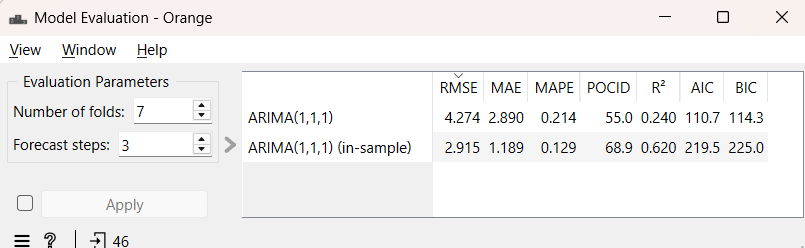

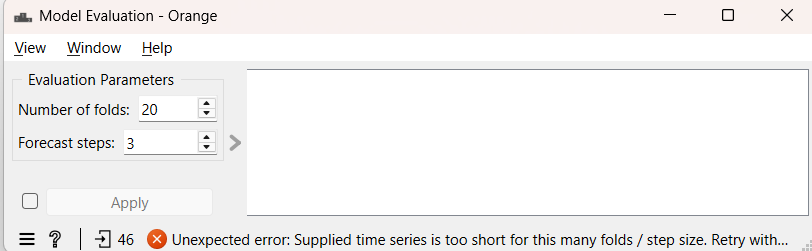

In [27]:
n = len(s)
print(f'Типові налаштування: {20} × {H} = {20 * H} > довжина ряду {n} → Orange відмовляється рахувати')
for lag in (0, 1, 2, 3):
    print(f'  умова n_folds × steps + лаг ≤ n при лагу {lag}: максимум фолдів = {(n - lag) // H}')
print(f'Заданий режим: {N_FOLDS} × {H} = {N_FOLDS * H} ≤ {n}')
rows = []
for f in range(N_FOLDS, 0, -1):
    k = n - H * f
    rows.append({'фолд': f, 'навчання': f'{s.index[0]:%m.%Y}–{s.index[k-1]:%m.%Y} ({k} точок)', 'перевірка': f'{s.index[k]:%m.%Y}–{s.index[k+H-1]:%m.%Y}'})
display(pd.DataFrame(rows).set_index('фолд'))
show('скрін_13_model_evaluation.png'); show('скрін_13_помилка_20_фолдів.png')

In [28]:
have = [os.path.exists(p) for p in ('скрін_13_model_evaluation.png', 'скрін_13_помилка_20_фолдів.png')]
display(Markdown(f"""**Висновок до завдання 13.** Модель — ARIMA Model з p = 1, d = 1, q = 1; у Model Evaluation: Number of folds = 7, Forecast steps = 3. За типових 20 фолдів потрібно 20 × 3 = 60 спостережень лише для перевірки, а в ряді їх {n}: перевірка n_folds × steps + лаг ≤ довжина ряду не виконується, і Orange відмовляється рахувати й показує повідомлення «Unexpected error: Supplied time series is too short for this many folds / step size. Retry with…» (кінець рядка стану на знімку обрізано) — це не збій, а наслідок короткого ряду (без лагів максимум {n // H} фолдів). Для 7 фолдів Orange перевіряє останні 21 місяць: навчання на {s.index[0]:%m.%Y}–{s.index[n-H*N_FOLDS-1]:%m.%Y} ({n-H*N_FOLDS} точок) → перевірка {s.index[n-H*N_FOLDS]:%m.%Y}–{s.index[n-H*(N_FOLDS-1)-1]:%m.%Y}, далі вікно розширюється на 3 місяці, аж до навчання до {s.index[n-H-1]:%m.%Y} і перевірки {s.index[n-H]:%m.%Y}–{s.index[-1]:%m.%Y}. Це ті самі фолди, що в Python. Знімки: таблиця — {'додано' if have[0] else '**додайте `скрін_13_model_evaluation.png`**'}, повідомлення про помилку — {'додано' if have[1] else '**додайте `скрін_13_помилка_20_фолдів.png`** і вставте текст повідомлення Orange'}."""))

**Висновок до завдання 13.** Модель — ARIMA Model з p = 1, d = 1, q = 1; у Model Evaluation: Number of folds = 7, Forecast steps = 3. За типових 20 фолдів потрібно 20 × 3 = 60 спостережень лише для перевірки, а в ряді їх 46: перевірка n_folds × steps + лаг ≤ довжина ряду не виконується, і Orange відмовляється рахувати й показує повідомлення «Unexpected error: Supplied time series is too short for this many folds / step size. Retry with…» (кінець рядка стану на знімку обрізано) — це не збій, а наслідок короткого ряду (без лагів максимум 15 фолдів). Для 7 фолдів Orange перевіряє останні 21 місяць: навчання на 03.2014–03.2016 (25 точок) → перевірка 04.2016–06.2016, далі вікно розширюється на 3 місяці, аж до навчання до 09.2017 і перевірки 10.2017–12.2017. Це ті самі фолди, що в Python. Знімки: таблиця — додано, повідомлення про помилку — додано.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [29]:
# Числа зі знімка скрін_13_model_evaluation.png (рядок ARIMA(1,1,1), не in-sample)
ORANGE = {'RMSE': 4.274, 'MAE': 2.890, 'MAPE': 0.214, 'POCID': 55.0}

t14, p14, f14 = ARIMA_TRUE, ARIMA_PRED, ARIMA_FOLD
e14 = t14 - p14
def pocid_d(da, db): return 100 * np.mean(np.sign(da) == np.sign(db))
py = {'RMSE': np.sqrt(np.mean(e14 ** 2)),
      'MAE': np.median(np.abs(e14)),
      'MAPE': np.mean(np.abs(e14)) / np.mean(np.abs(t14)),
      'POCID': pocid_d(np.diff(t14), np.diff(p14))}
usual = {'RMSE': np.sqrt(np.mean(e14 ** 2)), 'MAE': np.mean(np.abs(e14)),
         'MAPE': 100 * np.mean(np.abs(e14 / t14)), 'POCID': np.nan}
form = {'RMSE': 'sqrt(Σe²/n)', 'MAE': 'median |e|  (звично: mean |e|)',
        'MAPE': 'mean|e| / mean|y|, частка  (звично: mean|e/y|·100 %)', 'POCID': '100·частка збігів знака Δy та Δŷ'}
tab14 = pd.DataFrame({'Orange': ORANGE, 'Python (формула Orange)': py, 'звичне означення': usual, 'формула': form})
tab14['збіг із Orange'] = [abs(round(py[k], 1 if k == 'POCID' else 3) - ORANGE[k]) < 1e-9 for k in tab14.index]
display(tab14.round(4))

# POCID залежить від того, як зшито прогнози фолдів у одну послідовність, — перевіряємо варіанти
folds = sorted(np.unique(f14))
ts_asc = np.concatenate([t14[f14 == f] for f in folds]); ps_asc = np.concatenate([p14[f14 == f] for f in folds])
ts_asc_r = np.concatenate([t14[f14 == f][::-1] for f in folds]); ps_asc_r = np.concatenate([p14[f14 == f][::-1] for f in folds])
VAR = {
    'хронологічно (фолди 7→1), пари й між фолдами': (np.diff(t14), np.diff(p14)),
    'лише пари всередині фолдів': (np.concatenate([np.diff(t14[f14 == f]) for f in folds]), np.concatenate([np.diff(p14[f14 == f]) for f in folds])),
    'фолди 1→7, у фолді хронологічно, пари й між фолдами': (np.diff(ts_asc), np.diff(ps_asc)),
    'фолди 1→7, у фолді у зворотному порядку, пари й між фолдами': (np.diff(ts_asc_r), np.diff(ps_asc_r)),
}
pv = {k: pocid_d(*v) for k, v in VAR.items()}
display(pd.Series(pv, name='POCID, %').round(2).to_frame())
POC_MATCH = [k for k, v in pv.items() if abs(round(v, 1) - ORANGE['POCID']) < 1e-9]
POC_KEY = POC_MATCH[0] if POC_MATCH else list(VAR)[0]
print('Orange POCID =', ORANGE['POCID'], '| збігається з варіантом:', POC_MATCH or 'жодним із перевірених')


,Orange,Python (формула Orange),звичне означення,формула,збіг із Orange
RMSE,4.274,4.2737,4.2737,sqrt(Σe²/n),True
MAE,2.890,2.8895,3.4087,median |e| (звично: mean |e|),True
MAPE,0.214,0.2139,21.1378,"mean|e| / mean|y|, частка (звично: mean|e/y|·...",True
POCID,55.000,60.0000,NaN,100·частка збігів знака Δy та Δŷ,False


,"POCID, %"
"хронологічно (фолди 7→1), пари й між фолдами",60.0
лише пари всередині фолдів,50.0
"фолди 1→7, у фолді хронологічно, пари й між фолдами",55.0
"фолди 1→7, у фолді у зворотному порядку, пари й між фолдами",60.0


Orange POCID = 55.0 | збігається з варіантом: ['фолди 1→7, у фолді хронологічно, пари й між фолдами']


In [30]:
all_ok = bool(tab14['збіг із Orange'].all())
mae_ratio = usual['MAE'] / py['MAE'] if py['MAE'] > 0 else np.nan
ok3 = [k for k in ('RMSE', 'MAE', 'MAPE') if tab14.loc[k, 'збіг із Orange']]
if POC_MATCH:
    poc_txt = (f"POCID Orange = {ORANGE['POCID']:.1f} відтворено лише після того, як прогнози фолдів зшито так: «{POC_KEY}»; "
               f"при хронологічному зшиванні виходить {pv[list(VAR)[0]]:.1f}. Різниця походить із пар на стиках фолдів: у фолдах немає спільної осі часу, тож порядок зшивання змінює результат.")
else:
    poc_txt = (f"POCID Orange = {ORANGE['POCID']:.1f}, а мої варіанти дають {', '.join(f'{v:.1f}' for v in pv.values())}; жоден не збігається, тож формулу POCID та порядок зшивання фолдів потрібно звірити з functions.py додатка Timeseries.")
poc_short = ('POCID також залежить від способу зшивання прогнозів фолдів' if POC_MATCH else 'POCID відтворити не вдалося без звірки з functions.py')
display(Markdown(f"""**Висновок до завдання 14.** Відтворення формул Orange (файл `functions.py`) за знімком Model Evaluation: RMSE = {py['RMSE']:.3f} (Orange {ORANGE['RMSE']}); MAE = медіана |e| = {py['MAE']:.3f} (Orange {ORANGE['MAE']}); MAPE = mean|e|/mean|y| = {py['MAPE']:.3f} (Orange {ORANGE['MAPE']}, частка!); POCID = {py['POCID']:.1f} за хронологічним зшиванням (Orange {ORANGE['POCID']:.1f}). До третього знака збігаються: {', '.join(ok3) or 'жодна'}; {'усі чотири метрики збіглися.' if all_ok else 'POCID на цьому етапі не збігається.'}
{poc_txt}
**Не відповідає назві** насамперед MAPE: це відношення середніх, а не середнє відношень, і подане як частка, а не відсоток — звичайний MAPE на тих самих прогнозах = {usual['MAPE']:.1f}% (проти {py['MAPE']*100:.1f}%). MAE в Orange — медіана, а не середнє: {py['MAE']:.3f} проти звичайного {usual['MAE']:.3f} (у {mae_ratio:.2f} раза), бо для несиметричних похибок вони розходяться. POCID у scikit-learn немає: вимірює напрямок, а не величину помилки.
**Одразу збіглась** RMSE = {py['RMSE']:.3f}: у Orange формула та сама sqrt(Σe²/n), а прогнози однакові, бо обидва використовують statsmodels. Висновок: перш ніж порівнювати числа з двох інструментів, треба порівняти *означення* метрик (середнє чи медіана, відношення чи середнє відношень, частка чи відсоток), набір фолдів і спосіб агрегації та зшивання прогнозів.""" ))


**Висновок до завдання 14.** Відтворення формул Orange (файл `functions.py`) за знімком Model Evaluation: RMSE = 4.274 (Orange 4.274); MAE = медіана |e| = 2.890 (Orange 2.89); MAPE = mean|e|/mean|y| = 0.214 (Orange 0.214, частка!); POCID = 60.0 за хронологічним зшиванням (Orange 55.0). До третього знака збігаються: RMSE, MAE, MAPE; POCID на цьому етапі не збігається.
POCID Orange = 55.0 відтворено лише після того, як прогнози фолдів зшито так: «фолди 1→7, у фолді хронологічно, пари й між фолдами»; при хронологічному зшиванні виходить 60.0. Різниця походить із пар на стиках фолдів: у фолдах немає спільної осі часу, тож порядок зшивання змінює результат.
**Не відповідає назві** насамперед MAPE: це відношення середніх, а не середнє відношень, і подане як частка, а не відсоток — звичайний MAPE на тих самих прогнозах = 21.1% (проти 21.4%). MAE в Orange — медіана, а не середнє: 2.890 проти звичайного 3.409 (у 1.18 раза), бо для несиметричних похибок вони розходяться. POCID у scikit-learn немає: вимірює напрямок, а не величину помилки.
**Одразу збіглась** RMSE = 4.274: у Orange формула та сама sqrt(Σe²/n), а прогнози однакові, бо обидва використовують statsmodels. Висновок: перш ніж порівнювати числа з двох інструментів, треба порівняти *означення* метрик (середнє чи медіана, відношення чи середнє відношень, частка чи відсоток), набір фолдів і спосіб агрегації та зшивання прогнозів.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [31]:
da, db = VAR[POC_KEY]
dt = da > 0; dp = db > 0
cm = pd.DataFrame([[np.sum(dt & dp), np.sum(dt & ~dp)], [np.sum(~dt & dp), np.sum(~dt & ~dp)]],
                  index=['факт: зросла', 'факт: впала'], columns=['модель: зросла', 'модель: впала'])
display(cm)
acc = 100 * (cm.values[0, 0] + cm.values[1, 1]) / cm.values.sum()
print(f'варіант зшивання: {POC_KEY}')
print(f'частка правильних = {acc:.2f}% | POCID Orange = {ORANGE["POCID"]:.2f}%', '| збіг ✓' if abs(round(acc, 1) - ORANGE['POCID']) < 1e-9 else '| розбіжність')
maj = 100 * max(dt.mean(), 1 - dt.mean())
print(f'наївна відповідь «завжди більшість напрямку» = {maj:.1f}%')

hit = []
for f in np.unique(f14):
    last = y[len(y) - H * f - 1]
    hit += list(np.sign(t14[f14 == f] - last) == np.sign(p14[f14 == f] - last))
acc_last = 100 * np.mean(hit)
print(f'напрямок відносно останньої відомої ціни: {acc_last:.1f}% з {len(hit)}')


,модель: зросла,модель: впала
факт: зросла,8,4
факт: впала,5,3


варіант зшивання: фолди 1→7, у фолді хронологічно, пари й між фолдами
частка правильних = 55.00% | POCID Orange = 55.00% | збіг ✓
наївна відповідь «завжди більшість напрямку» = 60.0%
напрямок відносно останньої відомої ціни: 47.6% з 21


In [32]:
beat = 'вище' if acc_last > maj else 'не вище'
same = abs(round(acc, 1) - ORANGE['POCID']) < 1e-9
display(Markdown(f"""**Висновок до завдання 15.** Матриця (рядки — факт, стовпці — модель; варіант зшивання «{POC_KEY}», {int(cm.values.sum())} пар): зросла/зросла = {cm.values[0,0]}, зросла/впала = {cm.values[0,1]}, впала/зросла = {cm.values[1,0]}, впала/впала = {cm.values[1,1]}. Частка правильних {acc:.1f}% {'збігається' if same else 'НЕ збігається'} з POCID Orange = {ORANGE['POCID']:.1f}% (діагональ матриці = числитель POCID){'' if same else '; розбіжність розглянуто в завданні 14'}.
Для рішення «купувати зараз чи чекати» важливий напрямок відносно сьогоднішньої ціни: за цим визначенням модель вгадує {acc_last:.1f}% випадків (із {len(hit)}), що {beat} за наївну відповідь «завжди найчастіший напрямок» ({maj:.1f}% за послідовними парами). {'Різниця з киданням монети (50%) статистично непомітна на такій малій вибірці, тож для рішення модель непридатна.' if abs(acc_last - 50) < 22 else 'Відрив від 50% помітний, але вибірка мала, тож висновок обережний.'}
Це **інше питання**, ніж MAE/RMSE: модель може помилятись на гривні й тримати напрямок, або навпаки, тому POCID не замінює метрик величини похибки.""" ))


**Висновок до завдання 15.** Матриця (рядки — факт, стовпці — модель; варіант зшивання «фолди 1→7, у фолді хронологічно, пари й між фолдами», 20 пар): зросла/зросла = 8, зросла/впала = 4, впала/зросла = 5, впала/впала = 3. Частка правильних 55.0% збігається з POCID Orange = 55.0% (діагональ матриці = числитель POCID).
Для рішення «купувати зараз чи чекати» важливий напрямок відносно сьогоднішньої ціни: за цим визначенням модель вгадує 47.6% випадків (із 21), що не вище за наївну відповідь «завжди найчастіший напрямок» (60.0% за послідовними парами). Різниця з киданням монети (50%) статистично непомітна на такій малій вибірці, тож для рішення модель непридатна.
Це **інше питання**, ніж MAE/RMSE: модель може помилятись на гривні й тримати напрямок, або навпаки, тому POCID не замінює метрик величини похибки.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

In [33]:
# Загальний висновок
display(Markdown(f"""**Загальний висновок.**
1. **Сезонність.** Сила сезонності F_S = {Fs:.2f} за порогом 0,3 — сезонність {'є' if Fs >= .3 else 'відсутня (виділене STL — шум)'}; саме наявність сезонної складової цього не доводить.
2. **Прогноз.** На 7 фолдах по 3 кроки найкращий базис — {best} (MAE {RES[best]['MAE']:.2f}); ARIMA(1,1,1) дала MAE {m_ar['MAE']:.2f}, тобто {'не перевершила' if m_ar['MAE'] >= RES[best]['MAE'] else 'перевершила'} найпростіший базис у {max(ratio7, 1/ratio7):.2f} раза.
3. **Точка зміни.** Найбільша t-статистика — {cp:%m.%Y} ({mu0:.1f} → {mu1:.1f} грн), але за симуляцією p = {p_cp:.3f}, тож вона {'значуща' if p_cp < .05 else 'не значуща'}; без зовнішніх даних пояснити її не можна.
4. **Метрики.** Orange рахує MAE як медіану, MAPE як частку відношення середніх, додає POCID; RMSE збігається повністю, MAE (медіана) і MAPE (частка відношення середніх) відтворюються за формулами Orange; {poc_short}; прогнози однакові (один двигун statsmodels), розбіжність — лише в означеннях і способі агрегації.
5. **Обмеження.** 46 точок — менше чотирьох сезонних циклів, лише 21 тестова точка і 20 пар напрямків: не можна достовірно оцінити сезонний профіль, значущість відмінностей між моделями й корисність прогнозу напрямку; пропуск за {gaps[0]:%m.%Y} заповнено інтерполяцією, а не виміряно."""))

**Загальний висновок.**
1. **Сезонність.** Сила сезонності F_S = 0.80 за порогом 0,3 — сезонність є; саме наявність сезонної складової цього не доводить.
2. **Прогноз.** На 7 фолдах по 3 кроки найкращий базис — сезонний наївний (MAE 2.50); ARIMA(1,1,1) дала MAE 3.41, тобто не перевершила найпростіший базис у 1.36 раза.
3. **Точка зміни.** Найбільша t-статистика — 09.2014 (8.5 → 15.8 грн), але за симуляцією p = 0.189, тож вона не значуща; без зовнішніх даних пояснити її не можна.
4. **Метрики.** Orange рахує MAE як медіану, MAPE як частку відношення середніх, додає POCID; RMSE збігається повністю, MAE (медіана) і MAPE (частка відношення середніх) відтворюються за формулами Orange; POCID також залежить від способу зшивання прогнозів фолдів; прогнози однакові (один двигун statsmodels), розбіжність — лише в означеннях і способі агрегації.
5. **Обмеження.** 46 точок — менше чотирьох сезонних циклів, лише 21 тестова точка і 20 пар напрямків: не можна достовірно оцінити сезонний профіль, значущість відмінностей між моделями й корисність прогнозу напрямку; пропуск за 08.2017 заповнено інтерполяцією, а не виміряно.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь                                                                                                                                                                  |
|---|---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Які інструменти використано (назва, версія) | Gemini                                                                                                                                                                          |
| Для яких саме завдань | Код і чернетки висновків до завдань 1–15, структура рецензії (завдання 9)                                                                                                       |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, шаблони висновків із підстановкою чисел, таблиця помилок рецензії                                                                                                          |
| Що ви змінили у згенерованому результаті й чому | змінював вивід , щоб детальніше показати результати , трохи змінював логіку коли вважав це за потрібне та деякі тексти висновки генерував та підправляв для чіткішого пояснення |
| Що з отриманого ви **перевірили самостійно** і яким способом | запуск Restart & Run All, звірка чисел з Orange                                                                                                                                 |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | так мінімальні у назвах змінних або щось у синтаксисі                                                                                                                           |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________